<a href="https://colab.research.google.com/github/madhuraspatil/AIML_Practicle/blob/main/Regression_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Details

* **Name**: Parth Nandkishor Shingane
* **PRN**: 202401040210
* **Roll No**: 51
* **Division**: A (Batch: A2)
* **Github:**
---

### Title: Evaluating Regression Models for House Price Prediction

### AIM:
To predict house prices with different types of linear regression. Each model is first written from scratch using only NumPy, then built again with Scikit-learn, and then the two are compared with tables and plots.

Models covered: Simple, Multiple, Polynomial, Gradient Descent, Ridge, Lasso and Locally Weighted Regression.

### Objectives:
1. Look at the California housing data and see which features are linked to the house price.
2. Clean the data, scale the features and split it into training and testing parts.
3. For every model, write it from scratch, build it with a library, and compare the two.
4. Write Simple Linear Regression with the slope and intercept formulas.
5. Write Multiple Linear Regression with the normal equation.
6. Fit Polynomial Regression of different degrees and see where it starts to overfit.
7. Write Gradient Descent by hand and see how the learning rate and the number of iterations change the result.
8. Write Ridge and Lasso Regression by hand and see how the penalty changes the coefficients.
9. Write Locally Weighted Regression by hand and see how the bandwidth changes the fit.
10. Compare every model with MAE and MSE.

### Layout of this notebook
Part 1 is data preparation. Parts 2 to 8 each cover one model in three steps: **(A) from scratch**, **(B) with libraries**, **(C) comparison**. Part 9 compares all the models together.

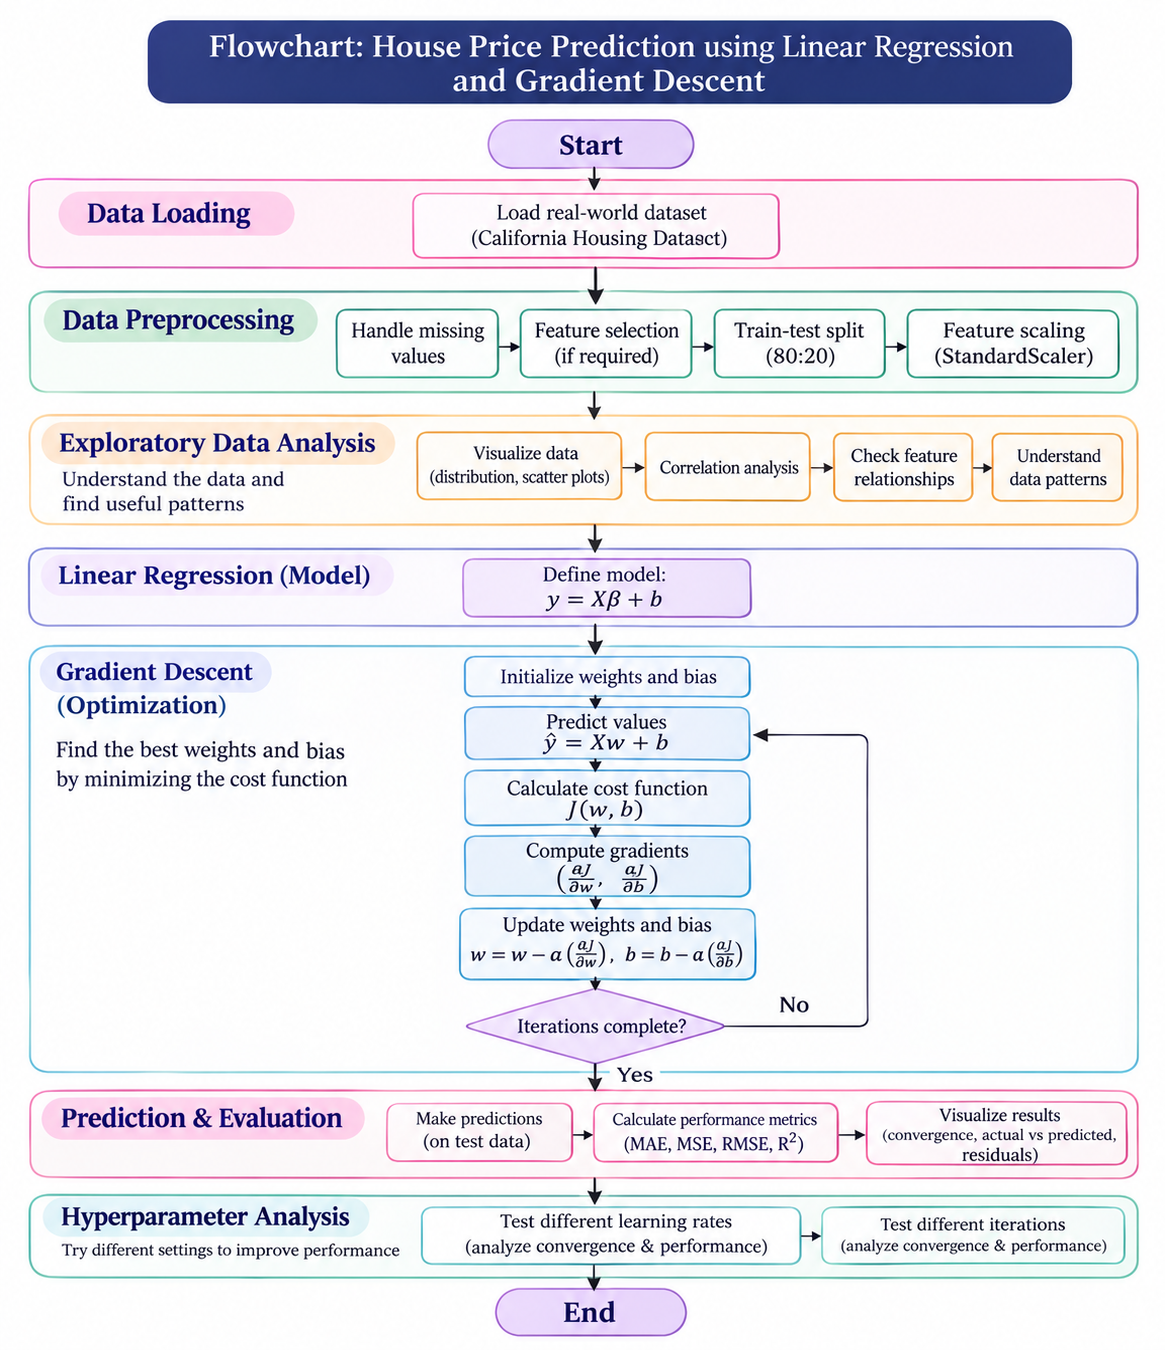

## Part 1: Data Preparation

The next two code cells load the California housing data, look at it, check how each feature is related to the price, split it into train (80%) and test (20%) parts, and scale the features.

Scaling matters for Gradient Descent, Ridge, Lasso and Locally Weighted Regression, because they depend on the size of the numbers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries loaded successfully!")

Libraries loaded successfully!



Dataset loaded successfully!
Number of rows: 20640
Number of features: 8

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Feature names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Missing values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

Statistical summary:
             MedInc      HouseAge      AveRooms     AveBedrms    Popu

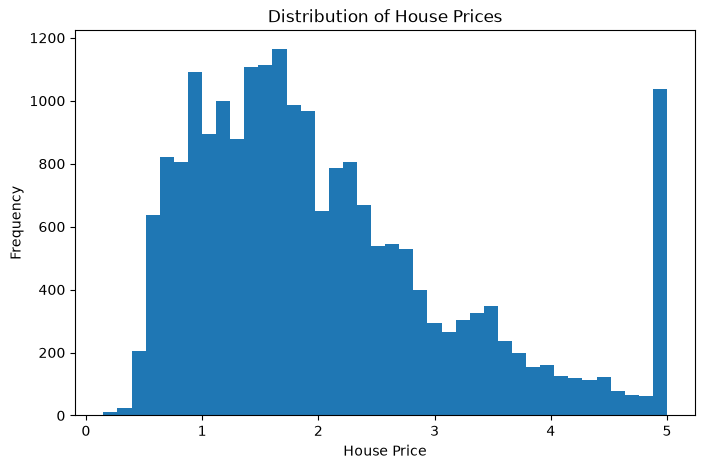


Correlation with House Price:
HousePrice    1.000000
MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: HousePrice, dtype: float64


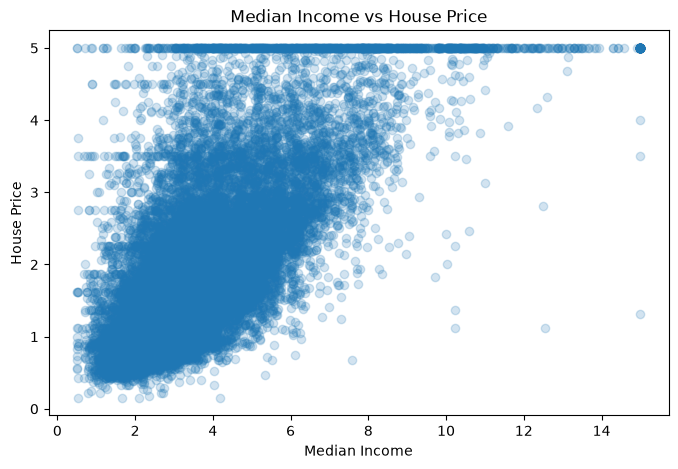


Training samples: 16512
Testing samples: 4128

Feature scaling completed!


In [2]:
# ============================================================
# 2. LOAD REAL HOUSE PRICE DATASET
# ============================================================

housing = fetch_california_housing()

X = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

y = pd.Series(
    housing.target,
    name="HousePrice"
)

print("\nDataset loaded successfully!")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFirst 5 rows:")
print(X.head())


# ============================================================
# 3. DATASET INFORMATION
# ============================================================

print("\nFeature names:")
print(X.columns.tolist())

print("\nMissing values:")
print(X.isnull().sum())

print("\nStatistical summary:")
print(X.describe())


# ============================================================
# 4. EXPLORATORY DATA ANALYSIS
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(y, bins=40)

plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.title("Distribution of House Prices")

plt.show()


# ============================================================
# 5. CORRELATION ANALYSIS
# ============================================================

data = X.copy()
data["HousePrice"] = y

correlation = data.corr()["HousePrice"].sort_values(
    ascending=False
)

print("\nCorrelation with House Price:")
print(correlation)


# ============================================================
# 6. MEDIAN INCOME VS HOUSE PRICE
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    X["MedInc"],
    y,
    alpha=0.2
)

plt.xlabel("Median Income")
plt.ylabel("House Price")
plt.title("Median Income vs House Price")

plt.show()


# ============================================================
# 7. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# 8. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed!")


In [3]:
# list that will hold the score of every model (filled as we go)
results = []

def add_result(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    results.append([name, mae, mse])
    return mae, mse

# put a column of ones in front of X so the first value of theta is the intercept
def add_bias(A):
    return np.c_[np.ones(len(A)), A]

y_tr = y_train.values
y_te = y_test.values

# a fixed set of 1500 test rows, used only to keep scatter plots light
rng = np.random.RandomState(0)
pick = rng.choice(len(y_te), 1500, replace=False)

print("Train rows:", len(y_tr), " Test rows:", len(y_te))

Train rows: 16512  Test rows: 4128


---
# Part 2: Simple Linear Regression

Simple linear regression uses **one** input feature. We take Median Income (`MedInc`) because it had the strongest link with price. The line is `y = m*x + c`.

### 2A. Simple Linear Regression from Scratch

The best line can be found directly with two formulas:

* `m = sum((x - mean_x) * (y - mean_y)) / sum((x - mean_x)^2)`
* `c = mean_y - m * mean_x`

Slope     : 0.41934
Intercept : 0.4446
MAE       : 0.6299
MSE       : 0.7091


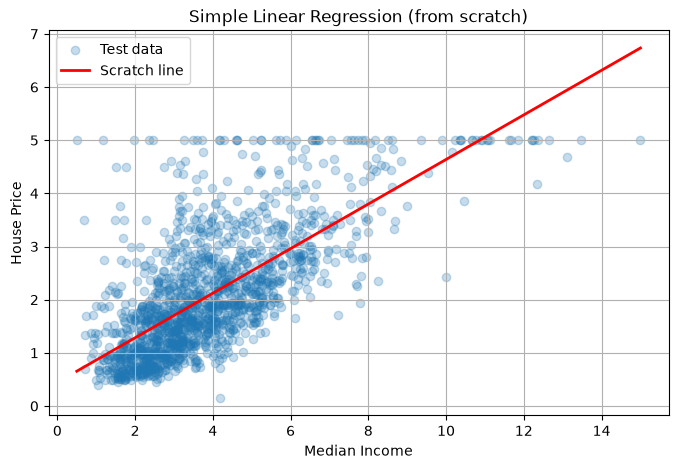

In [4]:
x_tr = X_train["MedInc"].values
x_te = X_test["MedInc"].values

x_mean = x_tr.mean()
y_mean = y_tr.mean()

slope = np.sum((x_tr - x_mean) * (y_tr - y_mean)) / np.sum((x_tr - x_mean) ** 2)
intercept = y_mean - slope * x_mean

pred_simple_scratch = slope * x_te + intercept

mae_s, mse_s = add_result("Simple LR (scratch)", y_te, pred_simple_scratch)
print("Slope     :", round(slope, 5))
print("Intercept :", round(intercept, 5))
print("MAE       :", round(mae_s, 4))
print("MSE       :", round(mse_s, 4))

line_x = np.linspace(x_te.min(), x_te.max(), 100)
plt.figure(figsize=(8, 5))
plt.scatter(x_te[pick], y_te[pick], alpha=0.25, label="Test data")
plt.plot(line_x, slope * line_x + intercept, color="red", linewidth=2, label="Scratch line")
plt.xlabel("Median Income")
plt.ylabel("House Price")
plt.title("Simple Linear Regression (from scratch)")
plt.legend()
plt.grid()
plt.show()

### 2B. Simple Linear Regression with Scikit-learn

`LinearRegression` does the same job in two lines: `fit` and `predict`.

Slope     : 0.41934
Intercept : 0.4446
MAE       : 0.6299
MSE       : 0.7091


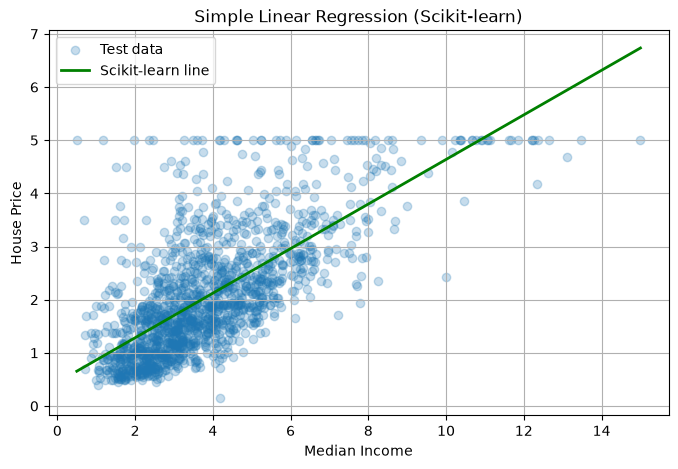

In [5]:
simple_lib = LinearRegression()
simple_lib.fit(x_tr.reshape(-1, 1), y_tr)
pred_simple_lib = simple_lib.predict(x_te.reshape(-1, 1))

mae_l, mse_l = add_result("Simple LR (Scikit-learn)", y_te, pred_simple_lib)
print("Slope     :", round(simple_lib.coef_[0], 5))
print("Intercept :", round(simple_lib.intercept_, 5))
print("MAE       :", round(mae_l, 4))
print("MSE       :", round(mse_l, 4))

plt.figure(figsize=(8, 5))
plt.scatter(x_te[pick], y_te[pick], alpha=0.25, label="Test data")
plt.plot(line_x, simple_lib.predict(line_x.reshape(-1, 1)), color="green", linewidth=2, label="Scikit-learn line")
plt.xlabel("Median Income")
plt.ylabel("House Price")
plt.title("Simple Linear Regression (Scikit-learn)")
plt.legend()
plt.grid()
plt.show()

### 2C. Comparison: Scratch vs Scikit-learn

We put the numbers side by side, draw both lines on the same plot, and plot the two sets of predictions against each other. If they are the same, all points sit on the diagonal.

    Value  Scratch  Scikit-learn
    Slope 0.419338      0.419338
Intercept 0.444597      0.444597
      MAE 0.629909      0.629909
      MSE 0.709116      0.709116

Largest difference in predictions: 5.329070518200751e-15


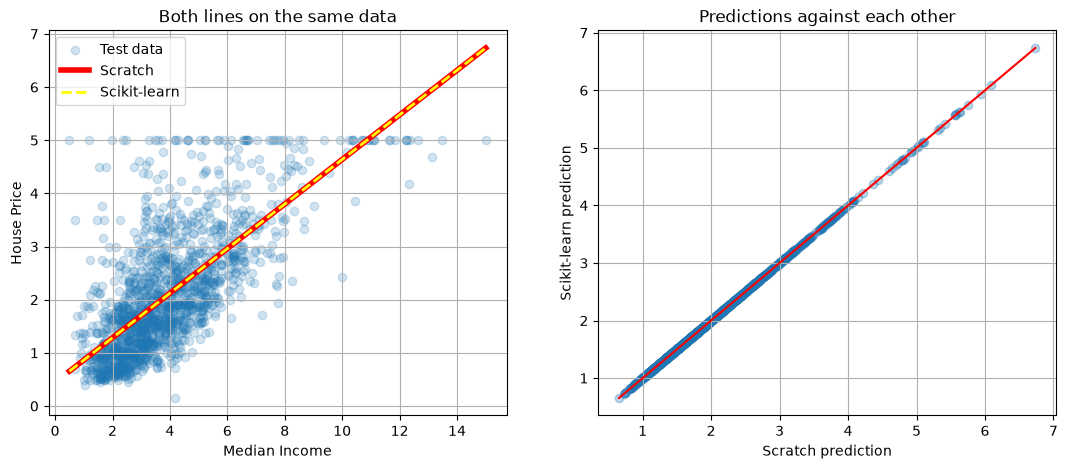

In [6]:
simple_cmp = pd.DataFrame({
    "Value": ["Slope", "Intercept", "MAE", "MSE"],
    "Scratch": [slope, intercept, mae_s, mse_s],
    "Scikit-learn": [simple_lib.coef_[0], simple_lib.intercept_, mae_l, mse_l]
})
print(simple_cmp.to_string(index=False))
print("\nLargest difference in predictions:", np.max(np.abs(pred_simple_scratch - pred_simple_lib)))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(x_te[pick], y_te[pick], alpha=0.2, label="Test data")
ax[0].plot(line_x, slope * line_x + intercept, color="red", linewidth=4, label="Scratch")
ax[0].plot(line_x, simple_lib.predict(line_x.reshape(-1, 1)), color="yellow", linestyle="--", linewidth=2, label="Scikit-learn")
ax[0].set_xlabel("Median Income")
ax[0].set_ylabel("House Price")
ax[0].set_title("Both lines on the same data")
ax[0].legend()
ax[0].grid()

ax[1].scatter(pred_simple_scratch[pick], pred_simple_lib[pick], alpha=0.3)
lims = [pred_simple_scratch.min(), pred_simple_scratch.max()]
ax[1].plot(lims, lims, color="red")
ax[1].set_xlabel("Scratch prediction")
ax[1].set_ylabel("Scikit-learn prediction")
ax[1].set_title("Predictions against each other")
ax[1].grid()

plt.show()

---
# Part 3: Multiple Linear Regression

Multiple linear regression uses **all 8 features** together: `y = b + w1*x1 + w2*x2 + ... + w8*x8`.

### 3A. Multiple Linear Regression from Scratch

There is a direct answer called the **normal equation**:

`theta = (X^T X)^-1 X^T y`

In the code we use `np.linalg.solve` instead of taking the inverse, because it is safer and faster.

MAE : 0.5332
MSE : 0.5559

Learned values:
   Feature   Scratch
 Intercept  2.071947
    MedInc  0.854383
  HouseAge  0.122546
  AveRooms -0.294410
 AveBedrms  0.339259
Population -0.002308
  AveOccup -0.040829
  Latitude -0.896929
 Longitude -0.869842


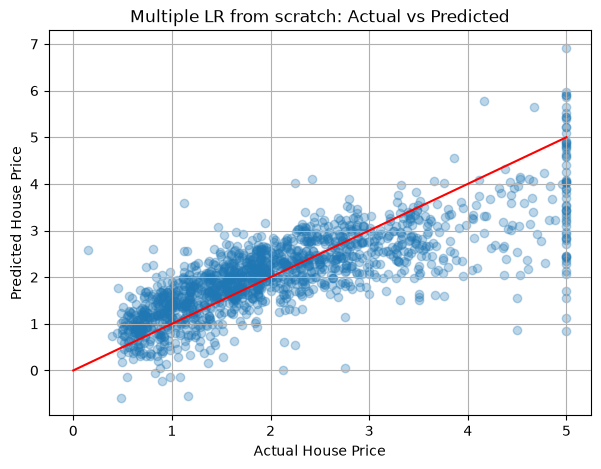

In [7]:
Xb_train = add_bias(X_train_scaled)
Xb_test = add_bias(X_test_scaled)

theta = np.linalg.solve(Xb_train.T @ Xb_train, Xb_train.T @ y_tr)
pred_multi_scratch = Xb_test @ theta

mae_ms, mse_ms = add_result("Multiple LR (scratch, normal eq.)", y_te, pred_multi_scratch)
print("MAE :", round(mae_ms, 4))
print("MSE :", round(mse_ms, 4))
print("\nLearned values:")
print(pd.DataFrame({"Feature": ["Intercept"] + list(X.columns), "Scratch": theta}).to_string(index=False))

plt.figure(figsize=(7, 5))
plt.scatter(y_te[pick], pred_multi_scratch[pick], alpha=0.3)
plt.plot([0, 5], [0, 5], color="red")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Multiple LR from scratch: Actual vs Predicted")
plt.grid()
plt.show()

### 3B. Multiple Linear Regression with Scikit-learn

MAE : 0.5332
MSE : 0.5559

Learned values:
   Feature  Scikit-learn
 Intercept      2.071947
    MedInc      0.854383
  HouseAge      0.122546
  AveRooms     -0.294410
 AveBedrms      0.339259
Population     -0.002308
  AveOccup     -0.040829
  Latitude     -0.896929
 Longitude     -0.869842


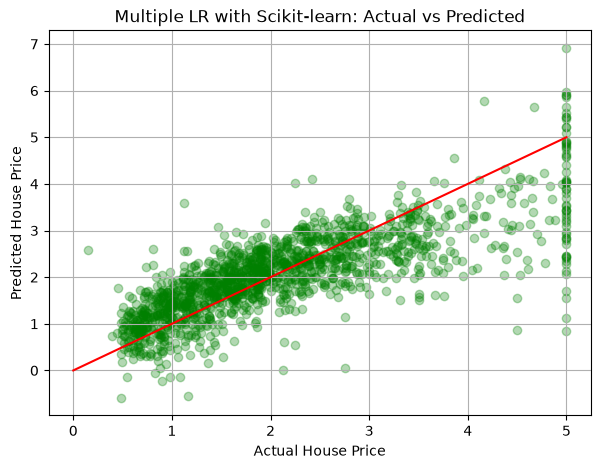

In [8]:
model = LinearRegression()
model.fit(X_train_scaled, y_tr)
pred_multi_lib = model.predict(X_test_scaled)

mae_ml, mse_ml = add_result("Multiple LR (Scikit-learn)", y_te, pred_multi_lib)
print("MAE :", round(mae_ml, 4))
print("MSE :", round(mse_ml, 4))
print("\nLearned values:")
print(pd.DataFrame({"Feature": ["Intercept"] + list(X.columns),
                    "Scikit-learn": np.r_[model.intercept_, model.coef_]}).to_string(index=False))

plt.figure(figsize=(7, 5))
plt.scatter(y_te[pick], pred_multi_lib[pick], alpha=0.3, color="green")
plt.plot([0, 5], [0, 5], color="red")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Multiple LR with Scikit-learn: Actual vs Predicted")
plt.grid()
plt.show()

### 3C. Comparison: Scratch vs Scikit-learn

   Feature   Scratch  Scikit-learn    Difference
 Intercept  2.071947      2.071947 -4.440892e-16
    MedInc  0.854383      0.854383  0.000000e+00
  HouseAge  0.122546      0.122546 -4.302114e-16
  AveRooms -0.294410     -0.294410  6.106227e-16
 AveBedrms  0.339259      0.339259 -1.665335e-15
Population -0.002308     -0.002308  7.181755e-16
  AveOccup -0.040829     -0.040829  4.649059e-16
  Latitude -0.896929     -0.896929  3.441691e-15
 Longitude -0.869842     -0.869842  3.774758e-15

       Scratch   Scikit-learn
MAE :  0.5332    0.5332
MSE :  0.5559    0.5559


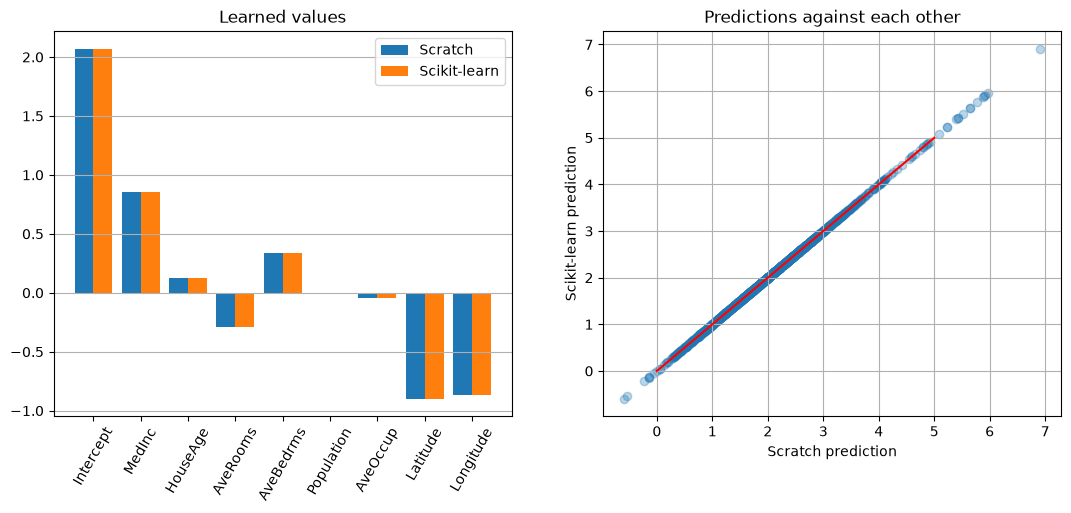

In [9]:
multi_cmp = pd.DataFrame({
    "Feature": ["Intercept"] + list(X.columns),
    "Scratch": theta,
    "Scikit-learn": np.r_[model.intercept_, model.coef_]
})
multi_cmp["Difference"] = multi_cmp["Scratch"] - multi_cmp["Scikit-learn"]
print(multi_cmp.to_string(index=False))

print("\n       Scratch   Scikit-learn")
print("MAE :  %.4f    %.4f" % (mae_ms, mae_ml))
print("MSE :  %.4f    %.4f" % (mse_ms, mse_ml))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

pos = np.arange(len(multi_cmp))
ax[0].bar(pos - 0.2, multi_cmp["Scratch"], width=0.4, label="Scratch")
ax[0].bar(pos + 0.2, multi_cmp["Scikit-learn"], width=0.4, label="Scikit-learn")
ax[0].set_xticks(pos)
ax[0].set_xticklabels(multi_cmp["Feature"], rotation=60)
ax[0].set_title("Learned values")
ax[0].legend()
ax[0].grid(axis="y")

ax[1].scatter(pred_multi_scratch[pick], pred_multi_lib[pick], alpha=0.3)
ax[1].plot([0, 5], [0, 5], color="red")
ax[1].set_xlabel("Scratch prediction")
ax[1].set_ylabel("Scikit-learn prediction")
ax[1].set_title("Predictions against each other")
ax[1].grid()

plt.show()

---
# Part 4: Polynomial Regression

A straight line cannot follow a curve. Polynomial regression fixes this by adding powers of the feature: `x, x^2, x^3 ...`. The model is still linear in its weights, so the same least squares method works.

We use `MedInc` again (scaled first, so the large powers do not blow up) and run two tests with every version:

1. **Full training data (16,512 rows), degrees 1 to 6.** With this many rows the curve is held in place, so a higher degree helps only a little.
2. **Only 30 training rows, degrees 1 to 9.** With so few rows a high degree can pass through the points but swing wildly in between. This is overfitting, and the test error shows it.

### 4A. Polynomial Regression from Scratch

We build the columns `1, x, x^2, ...` ourselves and solve with `np.linalg.lstsq`.

Scratch, full training data
 Degree  Train MSE  Test MSE
      1   0.699145  0.709116
      2   0.692989  0.703273
      3   0.680680  0.698296
      4   0.680542  0.698104
      5   0.680368  0.698716
      6   0.678843  0.695970


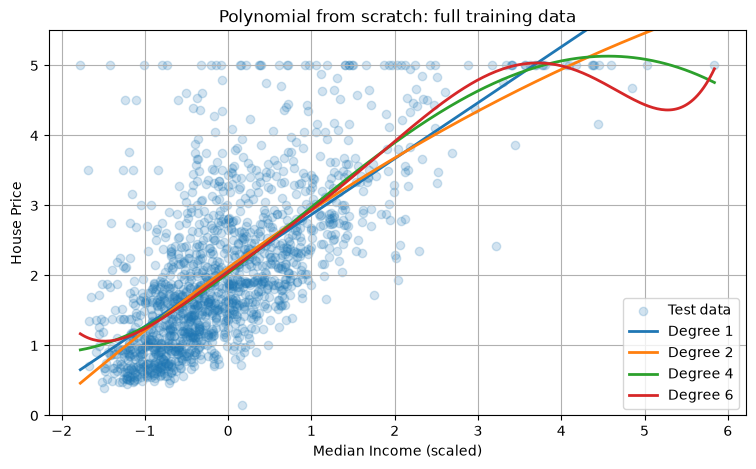


Scratch, only 30 training rows
 Degree  Train MSE (30 rows)     Test MSE
      1             0.383963 7.596697e-01
      2             0.383938 7.626437e-01
      3             0.374678 8.621861e-01
      5             0.350239 5.503530e+02
      7             0.297385 2.359024e+06
      9             0.287514 6.599217e+08


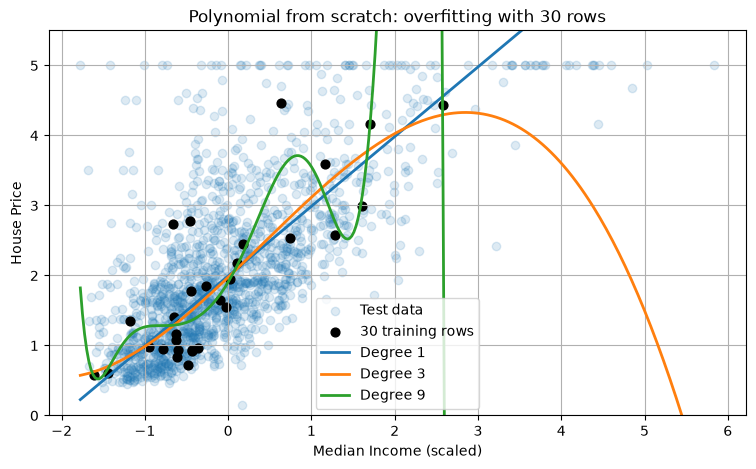

In [10]:
mu, sd = x_tr.mean(), x_tr.std()
xs_tr = (x_tr - mu) / sd
xs_te = (x_te - mu) / sd

def poly_columns(x, degree):
    # columns: 1, x, x^2, ..., x^degree
    return np.column_stack([x ** k for k in range(degree + 1)])

# ---------- test 1: full data ----------
degrees = [1, 2, 3, 4, 5, 6]
poly_s_rows = []
poly_s_coef = {}

for d in degrees:
    A_tr = poly_columns(xs_tr, d)
    A_te = poly_columns(xs_te, d)
    c, *_ = np.linalg.lstsq(A_tr, y_tr, rcond=None)
    poly_s_coef[d] = c
    poly_s_rows.append([d,
                        mean_squared_error(y_tr, A_tr @ c),
                        mean_squared_error(y_te, A_te @ c)])

poly_s_table = pd.DataFrame(poly_s_rows, columns=["Degree", "Train MSE", "Test MSE"])
print("Scratch, full training data")
print(poly_s_table.to_string(index=False))

# degree 3 goes to the final table
pred_poly_scratch = poly_columns(xs_te, 3) @ poly_s_coef[3]
add_result("Polynomial deg 3 (scratch)", y_te, pred_poly_scratch)

grid = np.linspace(xs_te.min(), xs_te.max(), 300)
plt.figure(figsize=(9, 5))
plt.scatter(xs_te[pick], y_te[pick], alpha=0.2, label="Test data")
for d in [1, 2, 4, 6]:
    plt.plot(grid, poly_columns(grid, d) @ poly_s_coef[d], linewidth=2, label="Degree %d" % d)
plt.ylim(0, 5.5)
plt.xlabel("Median Income (scaled)")
plt.ylabel("House Price")
plt.title("Polynomial from scratch: full training data")
plt.legend()
plt.grid()
plt.show()

# ---------- test 2: only 30 training rows ----------
rng2 = np.random.RandomState(5)
small = rng2.choice(len(xs_tr), 30, replace=False)
xs_small, y_small = xs_tr[small], y_tr[small]

small_degrees = [1, 2, 3, 5, 7, 9]
small_s_rows = []
small_s_coef = {}

for d in small_degrees:
    A_s = poly_columns(xs_small, d)
    c, *_ = np.linalg.lstsq(A_s, y_small, rcond=None)
    small_s_coef[d] = c
    small_s_rows.append([d,
                         mean_squared_error(y_small, A_s @ c),
                         mean_squared_error(y_te, poly_columns(xs_te, d) @ c)])

small_s_table = pd.DataFrame(small_s_rows, columns=["Degree", "Train MSE (30 rows)", "Test MSE"])
print("\nScratch, only 30 training rows")
print(small_s_table.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.scatter(xs_te[pick], y_te[pick], alpha=0.15, label="Test data")
plt.scatter(xs_small, y_small, color="black", s=40, label="30 training rows")
for d in [1, 3, 9]:
    plt.plot(grid, poly_columns(grid, d) @ small_s_coef[d], linewidth=2, label="Degree %d" % d)
plt.ylim(0, 5.5)
plt.xlabel("Median Income (scaled)")
plt.ylabel("House Price")
plt.title("Polynomial from scratch: overfitting with 30 rows")
plt.legend()
plt.grid()
plt.show()

### 4B. Polynomial Regression with Scikit-learn

`PolynomialFeatures` makes the power columns and `LinearRegression` fits them. We put both in a `make_pipeline`.

Scikit-learn, full training data
 Degree  Train MSE  Test MSE
      1   0.699145  0.709116
      2   0.692989  0.703273
      3   0.680680  0.698296
      4   0.680542  0.698104
      5   0.680368  0.698716
      6   0.678843  0.695970


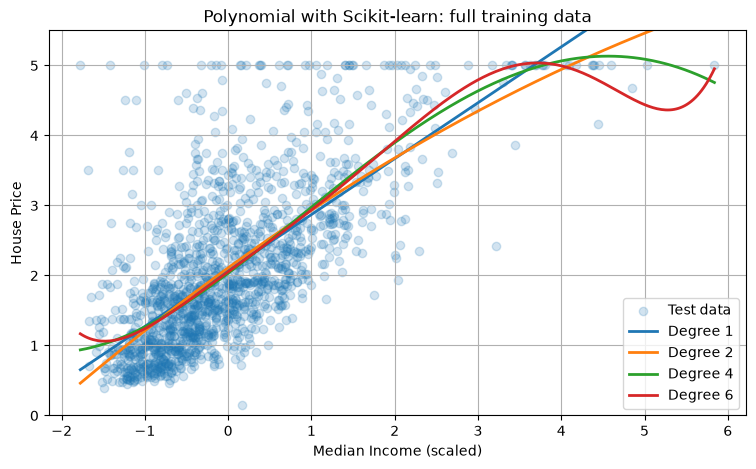


Scikit-learn, only 30 training rows
 Degree  Train MSE (30 rows)     Test MSE
      1             0.383963 7.596697e-01
      2             0.383938 7.626437e-01
      3             0.374678 8.621861e-01
      5             0.350239 5.503530e+02
      7             0.297385 2.359024e+06
      9             0.287514 6.599217e+08


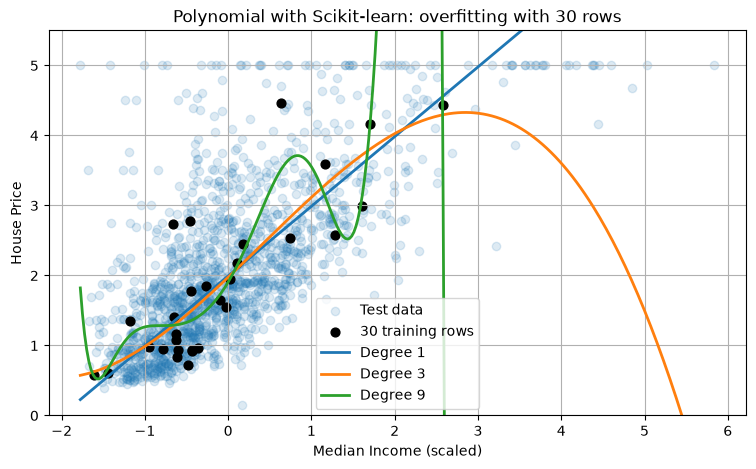

In [11]:
# ---------- test 1: full data ----------
poly_l_rows = []
poly_l_pipe = {}

for d in degrees:
    pipe = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
    pipe.fit(xs_tr.reshape(-1, 1), y_tr)
    poly_l_pipe[d] = pipe
    poly_l_rows.append([d,
                        mean_squared_error(y_tr, pipe.predict(xs_tr.reshape(-1, 1))),
                        mean_squared_error(y_te, pipe.predict(xs_te.reshape(-1, 1)))])

poly_l_table = pd.DataFrame(poly_l_rows, columns=["Degree", "Train MSE", "Test MSE"])
print("Scikit-learn, full training data")
print(poly_l_table.to_string(index=False))

pred_poly_lib = poly_l_pipe[3].predict(xs_te.reshape(-1, 1))
add_result("Polynomial deg 3 (Scikit-learn)", y_te, pred_poly_lib)

plt.figure(figsize=(9, 5))
plt.scatter(xs_te[pick], y_te[pick], alpha=0.2, label="Test data")
for d in [1, 2, 4, 6]:
    plt.plot(grid, poly_l_pipe[d].predict(grid.reshape(-1, 1)), linewidth=2, label="Degree %d" % d)
plt.ylim(0, 5.5)
plt.xlabel("Median Income (scaled)")
plt.ylabel("House Price")
plt.title("Polynomial with Scikit-learn: full training data")
plt.legend()
plt.grid()
plt.show()

# ---------- test 2: only 30 training rows ----------
small_l_rows = []
small_l_pipe = {}

for d in small_degrees:
    pipe = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
    pipe.fit(xs_small.reshape(-1, 1), y_small)
    small_l_pipe[d] = pipe
    small_l_rows.append([d,
                         mean_squared_error(y_small, pipe.predict(xs_small.reshape(-1, 1))),
                         mean_squared_error(y_te, pipe.predict(xs_te.reshape(-1, 1)))])

small_l_table = pd.DataFrame(small_l_rows, columns=["Degree", "Train MSE (30 rows)", "Test MSE"])
print("\nScikit-learn, only 30 training rows")
print(small_l_table.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.scatter(xs_te[pick], y_te[pick], alpha=0.15, label="Test data")
plt.scatter(xs_small, y_small, color="black", s=40, label="30 training rows")
for d in [1, 3, 9]:
    plt.plot(grid, small_l_pipe[d].predict(grid.reshape(-1, 1)), linewidth=2, label="Degree %d" % d)
plt.ylim(0, 5.5)
plt.xlabel("Median Income (scaled)")
plt.ylabel("House Price")
plt.title("Polynomial with Scikit-learn: overfitting with 30 rows")
plt.legend()
plt.grid()
plt.show()

### 4C. Comparison: Scratch vs Scikit-learn

Full training data
 Degree  Test MSE (scratch)  Test MSE (Scikit-learn)
      1            0.709116                 0.709116
      2            0.703273                 0.703273
      3            0.698296                 0.698296
      4            0.698104                 0.698104
      5            0.698716                 0.698716
      6            0.695970                 0.695970

Only 30 training rows
 Degree  Test MSE (scratch)  Test MSE (Scikit-learn)
      1        7.596697e-01             7.596697e-01
      2        7.626437e-01             7.626437e-01
      3        8.621861e-01             8.621861e-01
      5        5.503530e+02             5.503530e+02
      7        2.359024e+06             2.359024e+06
      9        6.599217e+08             6.599217e+08


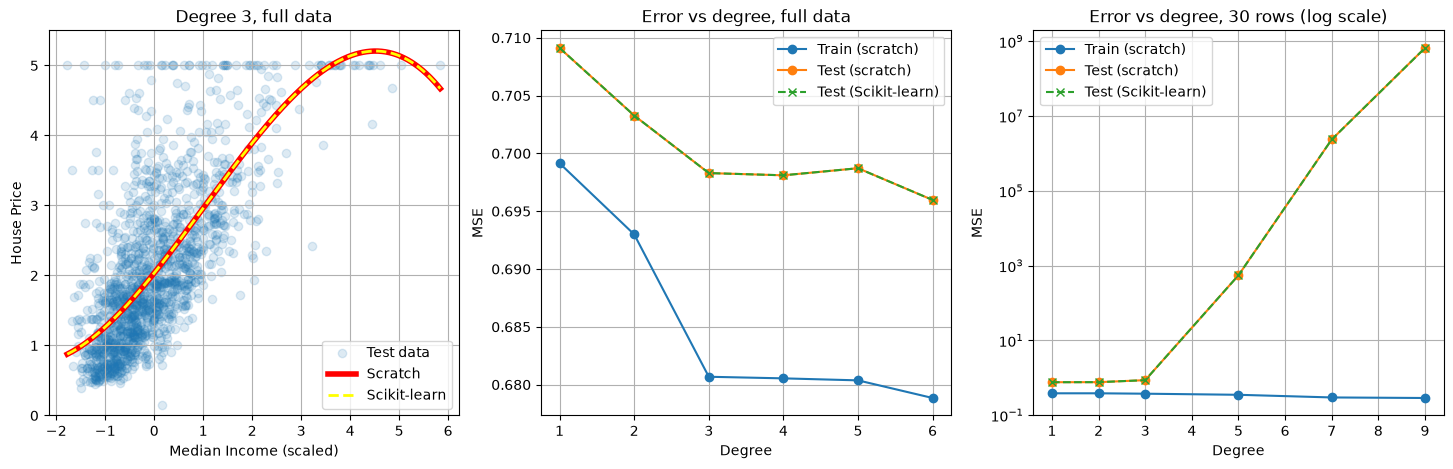

In [12]:
full_cmp = pd.DataFrame({
    "Degree": degrees,
    "Test MSE (scratch)": poly_s_table["Test MSE"],
    "Test MSE (Scikit-learn)": poly_l_table["Test MSE"]
})
print("Full training data")
print(full_cmp.to_string(index=False))

small_cmp = pd.DataFrame({
    "Degree": small_degrees,
    "Test MSE (scratch)": small_s_table["Test MSE"],
    "Test MSE (Scikit-learn)": small_l_table["Test MSE"]
})
print("\nOnly 30 training rows")
print(small_cmp.to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].scatter(xs_te[pick], y_te[pick], alpha=0.15, label="Test data")
ax[0].plot(grid, poly_columns(grid, 3) @ poly_s_coef[3], color="red", linewidth=4, label="Scratch")
ax[0].plot(grid, poly_l_pipe[3].predict(grid.reshape(-1, 1)), color="yellow", linestyle="--", linewidth=2, label="Scikit-learn")
ax[0].set_ylim(0, 5.5)
ax[0].set_title("Degree 3, full data")
ax[0].set_xlabel("Median Income (scaled)")
ax[0].set_ylabel("House Price")
ax[0].legend()
ax[0].grid()

ax[1].plot(degrees, poly_s_table["Train MSE"], marker="o", label="Train (scratch)")
ax[1].plot(degrees, poly_s_table["Test MSE"], marker="o", label="Test (scratch)")
ax[1].plot(degrees, poly_l_table["Test MSE"], marker="x", linestyle="--", label="Test (Scikit-learn)")
ax[1].set_title("Error vs degree, full data")
ax[1].set_xlabel("Degree")
ax[1].set_ylabel("MSE")
ax[1].legend()
ax[1].grid()

ax[2].plot(small_degrees, small_s_table["Train MSE (30 rows)"], marker="o", label="Train (scratch)")
ax[2].plot(small_degrees, small_s_table["Test MSE"], marker="o", label="Test (scratch)")
ax[2].plot(small_degrees, small_l_table["Test MSE"], marker="x", linestyle="--", label="Test (Scikit-learn)")
ax[2].set_yscale("log")
ax[2].set_title("Error vs degree, 30 rows (log scale)")
ax[2].set_xlabel("Degree")
ax[2].set_ylabel("MSE")
ax[2].legend()
ax[2].grid()

plt.show()

---
# Part 5: Gradient Descent

Gradient Descent finds the weights step by step instead of in one shot. Start with zero weights, find the slope of the cost, and take a small step downhill. Repeat many times.

* `w = w - learning_rate * dJ/dw`
* `b = b - learning_rate * dJ/db`

It is the method used when the data is too large for the direct formula.

### 5A. Gradient Descent from Scratch

The function below trains a linear model with gradient descent. After training we check the error, the convergence graph, actual vs predicted, and the residuals.


Gradient Descent training completed!

GRADIENT DESCENT RESULTS
MAE : 0.5477
MSE : 0.5672


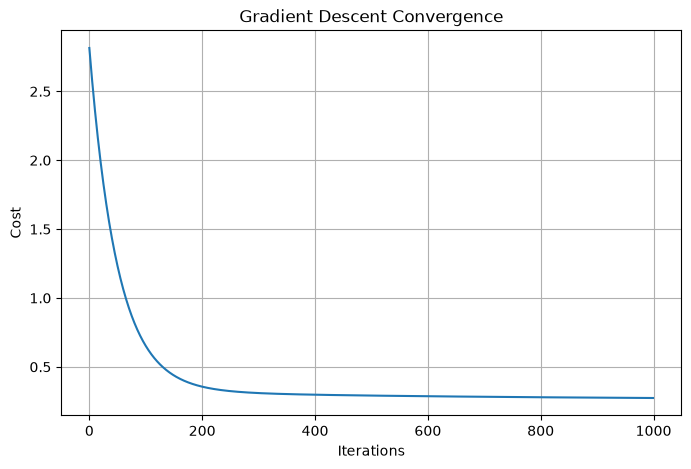

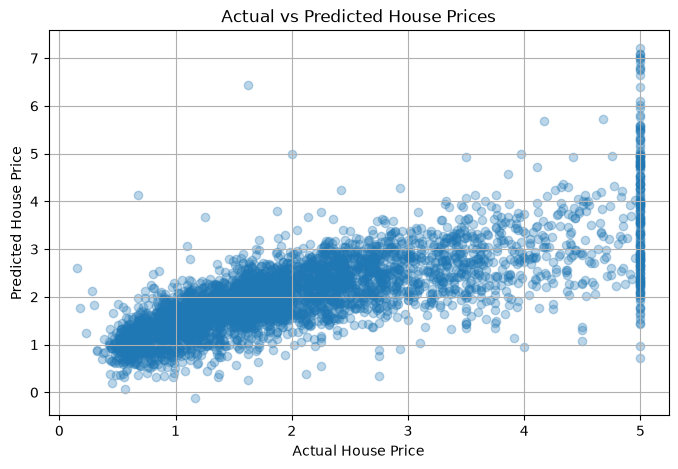

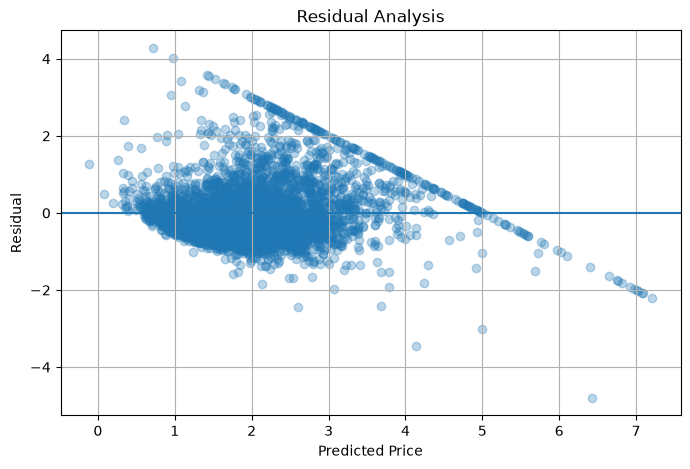

In [13]:
# ============================================================
# 9. GRADIENT DESCENT FUNCTION
# ============================================================

def gradient_descent(X, y, learning_rate, iterations):

    m = len(y)

    # Initialize weights
    weights = np.zeros(X.shape[1])

    # Initialize bias
    bias = 0

    cost_history = []

    for i in range(iterations):

        # Prediction
        predictions = np.dot(X, weights) + bias

        # Error
        error = predictions - y

        # Cost
        cost = np.mean(error ** 2) / 2

        cost_history.append(cost)

        # Gradients
        dw = np.dot(X.T, error) / m

        db = np.sum(error) / m

        # Update weights
        weights = weights - learning_rate * dw

        # Update bias
        bias = bias - learning_rate * db

    return weights, bias, cost_history


# ============================================================
# 10. TRAIN GRADIENT DESCENT MODEL
# ============================================================

learning_rate = 0.01
iterations = 1000

weights, bias, cost_history = gradient_descent(
    X_train_scaled,
    y_train.values,
    learning_rate,
    iterations
)

print("\nGradient Descent training completed!")


# ============================================================
# 11. PREDICTIONS
# ============================================================

y_pred_gd = (
    np.dot(X_test_scaled, weights) + bias
)


# ============================================================
# 12. PERFORMANCE METRICS
# ONLY MAE AND MSE
# ============================================================

mae_gd = mean_absolute_error(
    y_test,
    y_pred_gd
)

mse_gd = mean_squared_error(
    y_test,
    y_pred_gd
)

print("\n================================")
print("GRADIENT DESCENT RESULTS")
print("================================")

print("MAE :", round(mae_gd, 4))
print("MSE :", round(mse_gd, 4))


# ============================================================
# 13. CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    cost_history
)

plt.xlabel("Iterations")
plt.ylabel("Cost")

plt.title("Gradient Descent Convergence")

plt.grid()

plt.show()


# ============================================================
# 14. ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred_gd,
    alpha=0.3
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")

plt.title("Actual vs Predicted House Prices")

plt.grid()

plt.show()


# ============================================================
# 15. RESIDUAL ANALYSIS
# ============================================================

residuals = y_test.values - y_pred_gd

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_gd,
    residuals,
    alpha=0.3
)

plt.axhline(0)

plt.xlabel("Predicted Price")
plt.ylabel("Residual")

plt.title("Residual Analysis")

plt.grid()

plt.show()


In [14]:
add_result("Gradient Descent (scratch)", y_te, y_pred_gd)

(0.5476758462432726, 0.567185298608222)

**Learning rate and iteration tests (from scratch).** The learning rate is the size of each step. If it is too small, training is slow. If it is too large, training can fail to settle. We also check how the number of iterations changes the result.


LEARNING RATE EXPERIMENT
   Learning Rate  Final Cost       MAE       MSE
0         0.0001    2.361325  1.859651  4.643714
1         0.0010    0.655678  0.819111  1.302484
2         0.0100    0.273862  0.547676  0.567185
3         0.0500    0.259040  0.532852  0.556188


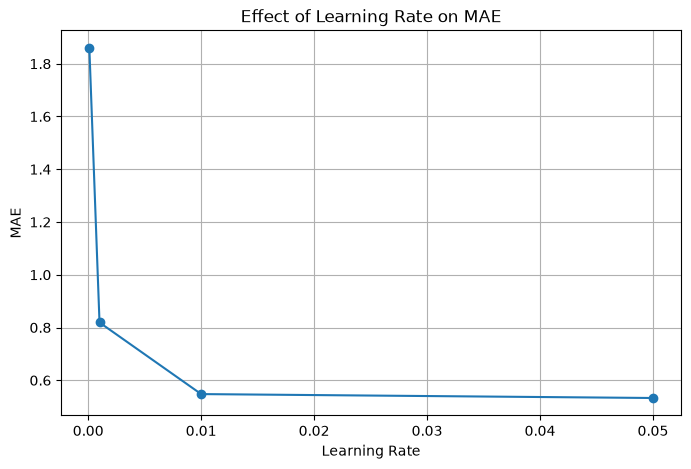

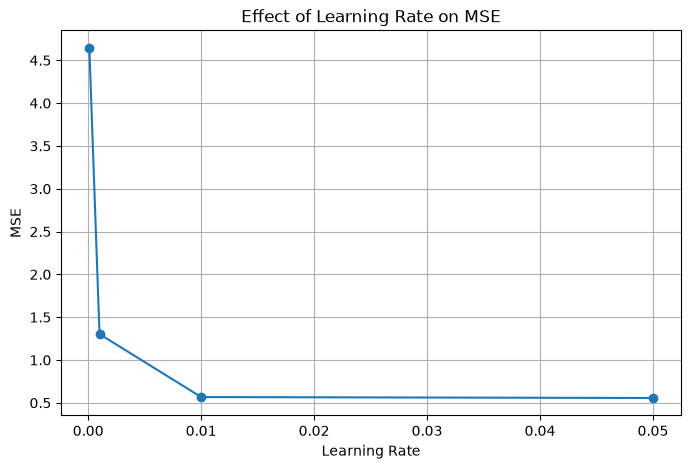


ITERATION EXPERIMENT
   Iterations  Final Cost       MAE       MSE
0         100    0.658797  0.816642  1.296588
1         500    0.291479  0.565250  0.596056
2        1000    0.273862  0.547676  0.567185
3        2000    0.262308  0.535211  0.554580
4        5000    0.259040  0.532851  0.556184


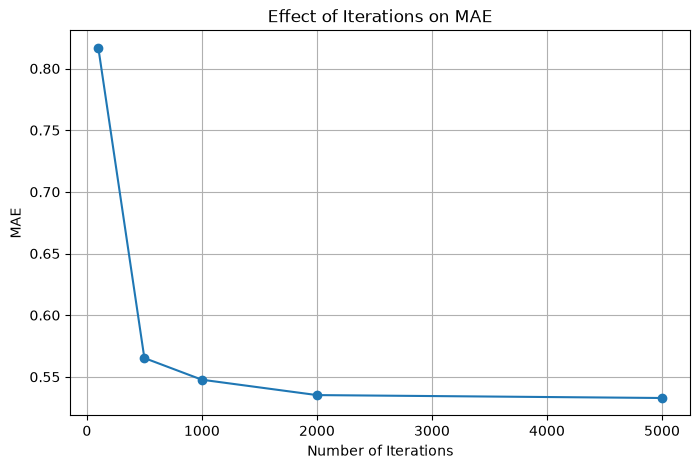

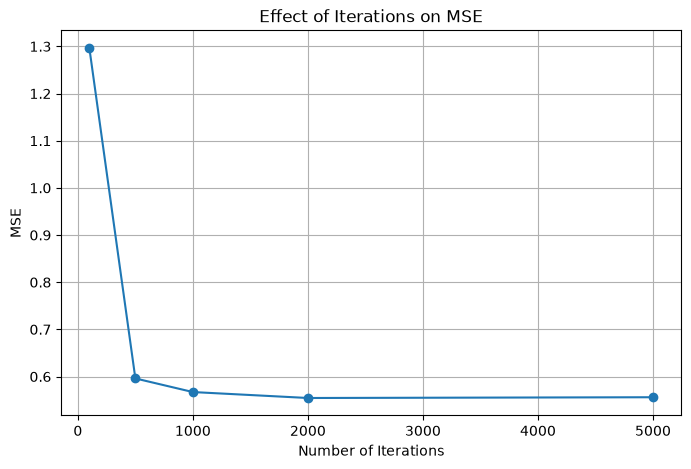

In [15]:
# ============================================================
# 19. LEARNING RATE EXPERIMENT
# ============================================================

learning_rates = [
    0.0001,
    0.001,
    0.01,
    0.05
]

lr_results = []

for lr in learning_rates:

    temp_weights, temp_bias, temp_cost = gradient_descent(
        X_train_scaled,
        y_train.values,
        lr,
        1000
    )

    temp_prediction = (
        np.dot(X_test_scaled, temp_weights)
        + temp_bias
    )

    temp_mae = mean_absolute_error(
        y_test,
        temp_prediction
    )

    temp_mse = mean_squared_error(
        y_test,
        temp_prediction
    )

    lr_results.append([
        lr,
        temp_cost[-1],
        temp_mae,
        temp_mse
    ])


lr_table = pd.DataFrame(
    lr_results,
    columns=[
        "Learning Rate",
        "Final Cost",
        "MAE",
        "MSE"
    ]
)

print("\n================================")
print("LEARNING RATE EXPERIMENT")
print("================================")

print(lr_table)


# ============================================================
# 20. LEARNING RATE GRAPH - MAE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    lr_table["Learning Rate"],
    lr_table["MAE"],
    marker="o"
)

plt.xlabel("Learning Rate")
plt.ylabel("MAE")

plt.title("Effect of Learning Rate on MAE")

plt.grid()

plt.show()


# ============================================================
# 21. LEARNING RATE GRAPH - MSE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    lr_table["Learning Rate"],
    lr_table["MSE"],
    marker="o"
)

plt.xlabel("Learning Rate")
plt.ylabel("MSE")

plt.title("Effect of Learning Rate on MSE")

plt.grid()

plt.show()


# ============================================================
# 22. ITERATION EXPERIMENT
# ============================================================

iteration_values = [
    100,
    500,
    1000,
    2000,
    5000
]

iteration_results = []

for it in iteration_values:

    temp_weights, temp_bias, temp_cost = gradient_descent(
        X_train_scaled,
        y_train.values,
        0.01,
        it
    )

    temp_prediction = (
        np.dot(X_test_scaled, temp_weights)
        + temp_bias
    )

    temp_mae = mean_absolute_error(
        y_test,
        temp_prediction
    )

    temp_mse = mean_squared_error(
        y_test,
        temp_prediction
    )

    iteration_results.append([
        it,
        temp_cost[-1],
        temp_mae,
        temp_mse
    ])


iteration_table = pd.DataFrame(
    iteration_results,
    columns=[
        "Iterations",
        "Final Cost",
        "MAE",
        "MSE"
    ]
)

print("\n================================")
print("ITERATION EXPERIMENT")
print("================================")

print(iteration_table)


# ============================================================
# 23. ITERATION GRAPH - MAE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    iteration_table["Iterations"],
    iteration_table["MAE"],
    marker="o"
)

plt.xlabel("Number of Iterations")
plt.ylabel("MAE")

plt.title("Effect of Iterations on MAE")

plt.grid()

plt.show()


# ============================================================
# 24. ITERATION GRAPH - MSE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    iteration_table["Iterations"],
    iteration_table["MSE"],
    marker="o"
)

plt.xlabel("Number of Iterations")
plt.ylabel("MSE")

plt.title("Effect of Iterations on MSE")

plt.grid()

plt.show()


### 5B. Gradient Descent with Scikit-learn

`SGDRegressor` is Scikit-learn's gradient descent. It is *stochastic*: it updates the weights using one row at a time instead of all rows, which is quicker on big data but a bit noisier.

MAE : 0.5299
MSE : 0.5506

Learned weights:
   Feature  SGDRegressor
    MedInc      0.812592
  HouseAge      0.114777
  AveRooms     -0.250275
 AveBedrms      0.302398
Population      0.002328
  AveOccup     -0.136505
  Latitude     -0.909316
 Longitude     -0.890612


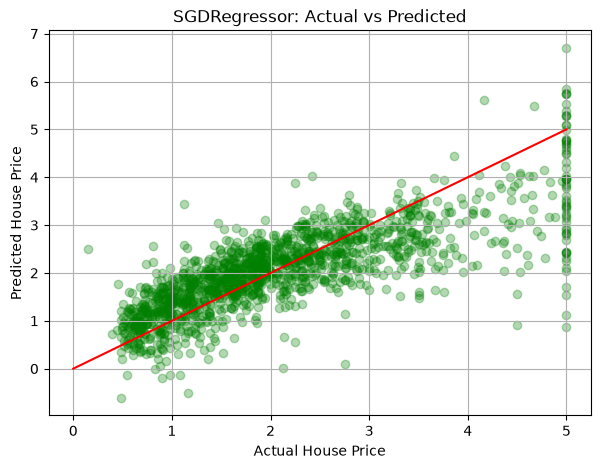

In [16]:
sgd = SGDRegressor(
    max_iter=1000,
    tol=1e-4,
    learning_rate="invscaling",
    eta0=0.01,
    random_state=42
)
sgd.fit(X_train_scaled, y_tr)
pred_sgd = sgd.predict(X_test_scaled)

mae_sgd, mse_sgd = add_result("Gradient Descent (SGDRegressor)", y_te, pred_sgd)
print("MAE :", round(mae_sgd, 4))
print("MSE :", round(mse_sgd, 4))
print("\nLearned weights:")
print(pd.DataFrame({"Feature": X.columns, "SGDRegressor": sgd.coef_}).to_string(index=False))

plt.figure(figsize=(7, 5))
plt.scatter(y_te[pick], pred_sgd[pick], alpha=0.3, color="green")
plt.plot([0, 5], [0, 5], color="red")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("SGDRegressor: Actual vs Predicted")
plt.grid()
plt.show()

### 5C. Comparison: Our Gradient Descent vs SGDRegressor

We also add the exact answer from `LinearRegression` (Part 3) as a reference, so we can see how close each gradient descent version gets.

   Feature    Our GD  SGDRegressor  Exact (LinearRegression)
    MedInc  0.828944      0.812592                  0.854383
  HouseAge  0.178531      0.114777                  0.122546
  AveRooms -0.137949     -0.250275                 -0.294410
 AveBedrms  0.156692      0.302398                  0.339259
Population  0.016815      0.002328                 -0.002308
  AveOccup -0.045229     -0.136505                 -0.040829
  Latitude -0.487056     -0.909316                 -0.896929
 Longitude -0.451471     -0.890612                 -0.869842

          Our GD    SGDRegressor   Exact
MAE :     0.5477    0.5299         0.5332
MSE :     0.5672    0.5506         0.5559


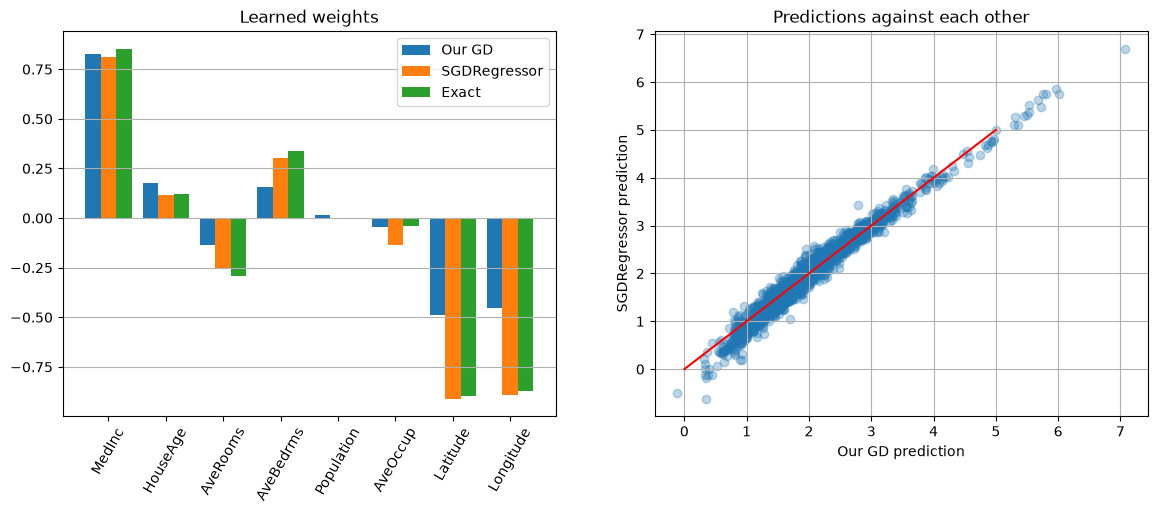

First 10 test rows:
 Actual  Our GD  SGDRegressor
  0.477   0.881         0.723
  0.458   1.653         1.768
  5.000   2.502         2.686
  2.186   2.765         2.808
  2.780   2.355         2.619
  1.587   2.094         1.991
  1.982   2.691         2.606
  1.575   2.178         2.135
  3.400   2.354         2.723
  4.466   4.056         3.827


In [17]:
gd_cmp = pd.DataFrame({
    "Feature": X.columns,
    "Our GD": weights,
    "SGDRegressor": sgd.coef_,
    "Exact (LinearRegression)": model.coef_
})
print(gd_cmp.to_string(index=False))

print("\n          Our GD    SGDRegressor   Exact")
print("MAE :     %.4f    %.4f         %.4f" % (mae_gd, mae_sgd, mae_ml))
print("MSE :     %.4f    %.4f         %.4f" % (mse_gd, mse_sgd, mse_ml))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

pos = np.arange(len(X.columns))
ax[0].bar(pos - 0.27, gd_cmp["Our GD"], width=0.27, label="Our GD")
ax[0].bar(pos, gd_cmp["SGDRegressor"], width=0.27, label="SGDRegressor")
ax[0].bar(pos + 0.27, gd_cmp["Exact (LinearRegression)"], width=0.27, label="Exact")
ax[0].set_xticks(pos)
ax[0].set_xticklabels(X.columns, rotation=60)
ax[0].set_title("Learned weights")
ax[0].legend()
ax[0].grid(axis="y")

ax[1].scatter(y_pred_gd[pick], pred_sgd[pick], alpha=0.3)
ax[1].plot([0, 5], [0, 5], color="red")
ax[1].set_xlabel("Our GD prediction")
ax[1].set_ylabel("SGDRegressor prediction")
ax[1].set_title("Predictions against each other")
ax[1].grid()

plt.show()

print("First 10 test rows:")
print(pd.DataFrame({"Actual": y_te[:10], "Our GD": y_pred_gd[:10], "SGDRegressor": pred_sgd[:10]}).round(3).to_string(index=False))

---
# Part 6: Ridge Regression (L2)

Ridge adds a penalty on the size of the weights, so the weights cannot grow too big. This helps when features are related to each other or when the model overfits.

`Cost = sum((y - y_pred)^2) + alpha * sum(w^2)`

A bigger `alpha` means stronger shrinking. `alpha = 0` is the same as normal linear regression. We try these alphas: 0.01, 1, 10, 100, 1000, 10000.

### 6A. Ridge Regression from Scratch

Ridge also has a direct answer: `theta = (X^T X + alpha * I)^-1 X^T y`. The intercept is not penalised, so the first value of `I` is set to 0.

   Alpha      MAE      MSE
    0.01 0.533200 0.555891
    1.00 0.533193 0.555855
   10.00 0.533138 0.555535
  100.00 0.533014 0.553266
 1000.00 0.549348 0.565923
10000.00 0.654386 0.724432


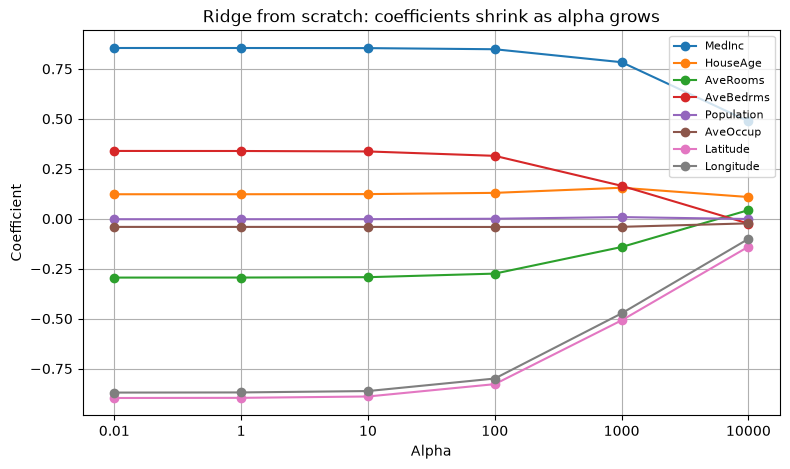

In [18]:
def ridge_scratch(Xs, y, alpha):
    Xb = add_bias(Xs)
    I = np.eye(Xb.shape[1])
    I[0, 0] = 0                      # do not penalise the intercept
    return np.linalg.solve(Xb.T @ Xb + alpha * I, Xb.T @ y)

alphas = [0.01, 1, 10, 100, 1000, 10000]
ridge_s_rows = []
ridge_s_coef = {}
ridge_s_pred = {}

for a in alphas:
    th = ridge_scratch(X_train_scaled, y_tr, a)
    p = Xb_test @ th
    ridge_s_coef[a] = th[1:]
    ridge_s_pred[a] = p
    ridge_s_rows.append([a, mean_absolute_error(y_te, p), mean_squared_error(y_te, p)])

ridge_s_table = pd.DataFrame(ridge_s_rows, columns=["Alpha", "MAE", "MSE"])
print(ridge_s_table.to_string(index=False))

add_result("Ridge alpha=10 (scratch)", y_te, ridge_s_pred[10])

plt.figure(figsize=(9, 5))
for i, name in enumerate(X.columns):
    plt.plot(range(len(alphas)), [ridge_s_coef[a][i] for a in alphas], marker="o", label=name)
plt.xticks(range(len(alphas)), alphas)
plt.xlabel("Alpha")
plt.ylabel("Coefficient")
plt.title("Ridge from scratch: coefficients shrink as alpha grows")
plt.legend(fontsize=8)
plt.grid()
plt.show()

### 6B. Ridge Regression with Scikit-learn

   Alpha      MAE      MSE
    0.01 0.533200 0.555891
    1.00 0.533193 0.555855
   10.00 0.533138 0.555535
  100.00 0.533014 0.553266
 1000.00 0.549348 0.565923
10000.00 0.654386 0.724432


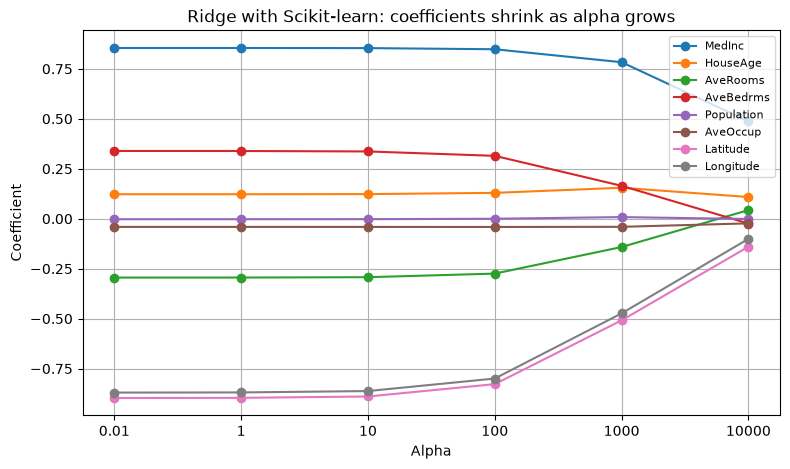

In [19]:
ridge_l_rows = []
ridge_l_coef = {}
ridge_l_pred = {}

for a in alphas:
    lib = Ridge(alpha=a)
    lib.fit(X_train_scaled, y_tr)
    p = lib.predict(X_test_scaled)
    ridge_l_coef[a] = lib.coef_
    ridge_l_pred[a] = p
    ridge_l_rows.append([a, mean_absolute_error(y_te, p), mean_squared_error(y_te, p)])

ridge_l_table = pd.DataFrame(ridge_l_rows, columns=["Alpha", "MAE", "MSE"])
print(ridge_l_table.to_string(index=False))

add_result("Ridge alpha=10 (Scikit-learn)", y_te, ridge_l_pred[10])

plt.figure(figsize=(9, 5))
for i, name in enumerate(X.columns):
    plt.plot(range(len(alphas)), [ridge_l_coef[a][i] for a in alphas], marker="o", label=name)
plt.xticks(range(len(alphas)), alphas)
plt.xlabel("Alpha")
plt.ylabel("Coefficient")
plt.title("Ridge with Scikit-learn: coefficients shrink as alpha grows")
plt.legend(fontsize=8)
plt.grid()
plt.show()

### 6C. Comparison: Scratch vs Scikit-learn

   Alpha  MSE (scratch)  MSE (Scikit-learn)  Max coef difference
    0.01       0.555891            0.555891         2.609024e-15
    1.00       0.555855            0.555855         3.330669e-15
   10.00       0.555535            0.555535         3.330669e-15
  100.00       0.553266            0.553266         1.776357e-15
 1000.00       0.565923            0.565923         4.440892e-16
10000.00       0.724432            0.724432         6.938894e-17


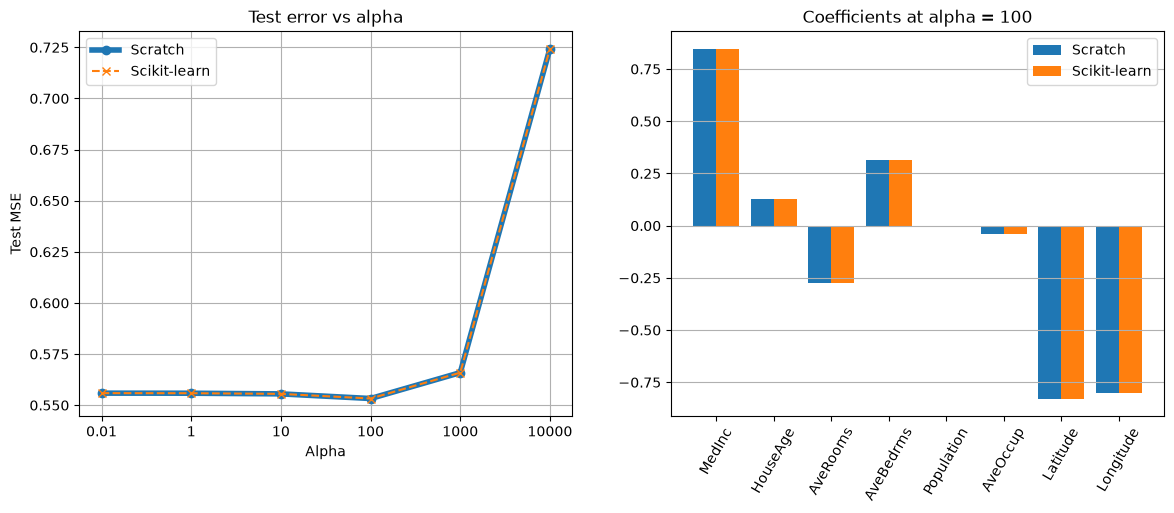

In [20]:
ridge_cmp = pd.DataFrame({
    "Alpha": alphas,
    "MSE (scratch)": ridge_s_table["MSE"],
    "MSE (Scikit-learn)": ridge_l_table["MSE"],
    "Max coef difference": [np.max(np.abs(ridge_s_coef[a] - ridge_l_coef[a])) for a in alphas]
})
print(ridge_cmp.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(range(len(alphas)), ridge_s_table["MSE"], marker="o", linewidth=4, label="Scratch")
ax[0].plot(range(len(alphas)), ridge_l_table["MSE"], marker="x", linestyle="--", label="Scikit-learn")
ax[0].set_xticks(range(len(alphas)))
ax[0].set_xticklabels(alphas)
ax[0].set_xlabel("Alpha")
ax[0].set_ylabel("Test MSE")
ax[0].set_title("Test error vs alpha")
ax[0].legend()
ax[0].grid()

pos = np.arange(len(X.columns))
ax[1].bar(pos - 0.2, ridge_s_coef[100], width=0.4, label="Scratch")
ax[1].bar(pos + 0.2, ridge_l_coef[100], width=0.4, label="Scikit-learn")
ax[1].set_xticks(pos)
ax[1].set_xticklabels(X.columns, rotation=60)
ax[1].set_title("Coefficients at alpha = 100")
ax[1].legend()
ax[1].grid(axis="y")

plt.show()

---
# Part 7: Lasso Regression (L1)

Lasso also adds a penalty, but it uses the absolute size of the weights:

`Cost = (1 / 2n) * sum((y - y_pred)^2) + alpha * sum(|w|)`

The special thing about Lasso is that it can push some weights **exactly to zero**, so it also works as a feature selector. We try these alphas: 0.001, 0.01, 0.05, 0.1, 0.3, 0.6.

### 7A. Lasso Regression from Scratch

There is no simple formula for Lasso, because `|w|` has a sharp corner at zero. We use **coordinate descent**: update one weight at a time while the others stay fixed. Each update uses the *soft threshold* rule:

`w_j = soft(rho_j, alpha) / z_j`, where `soft(r, a) = sign(r) * max(|r| - a, 0)`

If `rho_j` is smaller than `alpha`, the weight becomes zero.

 Alpha      MAE      MSE  Zero weights
 0.001 0.533148 0.554485             0
 0.010 0.535331 0.548239             1
 0.050 0.581983 0.615123             4
 0.100 0.622201 0.679629             5
 0.300 0.684274 0.789049             7
 0.600 0.806228 1.044796             7

Weights at alpha = 0.1
   Feature   Scratch
    MedInc  0.710598
  HouseAge  0.106453
  AveRooms -0.000000
 AveBedrms  0.000000
Population -0.000000
  AveOccup -0.000000
  Latitude -0.011469
 Longitude -0.000000


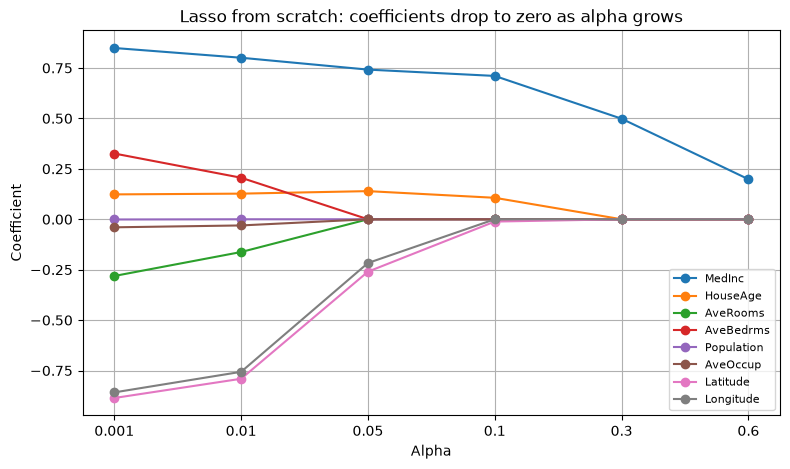

In [21]:
def soft_threshold(rho, lam):
    return np.sign(rho) * max(abs(rho) - lam, 0.0)

def lasso_scratch(Xs, y, alpha, max_iter=1000, tol=1e-7):
    n, d = Xs.shape
    y_avg = y.mean()
    yc = y - y_avg                    # centre y, the intercept is just its mean
    w = np.zeros(d)
    z = (Xs ** 2).mean(axis=0)

    for it in range(max_iter):
        w_old = w.copy()
        for j in range(d):
            # residual without the effect of feature j
            r_j = yc - Xs @ w + Xs[:, j] * w[j]
            rho = (Xs[:, j] @ r_j) / n
            w[j] = soft_threshold(rho, alpha) / z[j]
        if np.max(np.abs(w - w_old)) < tol:
            break
    return w, y_avg

lasso_alphas = [0.001, 0.01, 0.05, 0.1, 0.3, 0.6]
lasso_s_rows = []
lasso_s_coef = {}
lasso_s_pred = {}

for a in lasso_alphas:
    w_s, b_s = lasso_scratch(X_train_scaled, y_tr, a)
    p = X_test_scaled @ w_s + b_s
    lasso_s_coef[a] = w_s
    lasso_s_pred[a] = p
    lasso_s_rows.append([a, mean_absolute_error(y_te, p), mean_squared_error(y_te, p),
                         int(np.sum(np.abs(w_s) < 1e-8))])

lasso_s_table = pd.DataFrame(lasso_s_rows, columns=["Alpha", "MAE", "MSE", "Zero weights"])
print(lasso_s_table.to_string(index=False))

add_result("Lasso alpha=0.01 (scratch)", y_te, lasso_s_pred[0.01])

print("\nWeights at alpha = 0.1")
print(pd.DataFrame({"Feature": X.columns, "Scratch": lasso_s_coef[0.1]}).to_string(index=False))

plt.figure(figsize=(9, 5))
for i, name in enumerate(X.columns):
    plt.plot(range(len(lasso_alphas)), [lasso_s_coef[a][i] for a in lasso_alphas], marker="o", label=name)
plt.xticks(range(len(lasso_alphas)), lasso_alphas)
plt.xlabel("Alpha")
plt.ylabel("Coefficient")
plt.title("Lasso from scratch: coefficients drop to zero as alpha grows")
plt.legend(fontsize=8)
plt.grid()
plt.show()

### 7B. Lasso Regression with Scikit-learn

 Alpha      MAE      MSE  Zero weights
 0.001 0.533145 0.554491             0
 0.010 0.535326 0.548255             1
 0.050 0.582035 0.615208             4
 0.100 0.622201 0.679629             5
 0.300 0.684274 0.789049             7
 0.600 0.806228 1.044796             7

Weights at alpha = 0.1
   Feature  Scikit-learn
    MedInc      0.710598
  HouseAge      0.106453
  AveRooms     -0.000000
 AveBedrms      0.000000
Population     -0.000000
  AveOccup     -0.000000
  Latitude     -0.011469
 Longitude     -0.000000


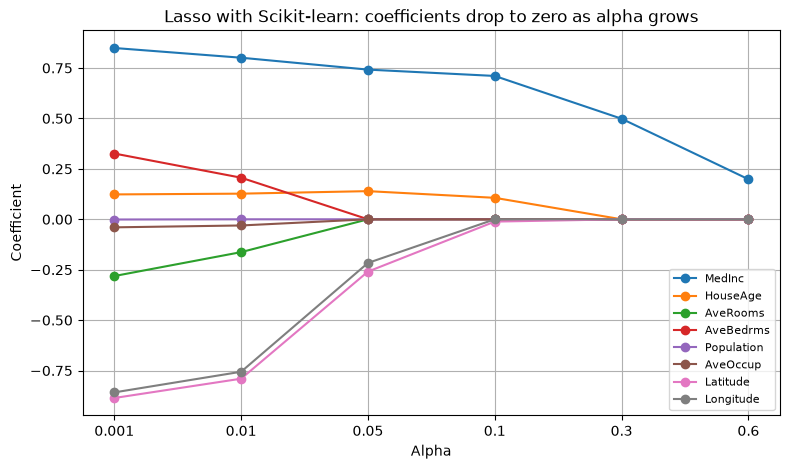

In [22]:
lasso_l_rows = []
lasso_l_coef = {}
lasso_l_pred = {}

for a in lasso_alphas:
    lib = Lasso(alpha=a, max_iter=100000)
    lib.fit(X_train_scaled, y_tr)
    p = lib.predict(X_test_scaled)
    lasso_l_coef[a] = lib.coef_
    lasso_l_pred[a] = p
    lasso_l_rows.append([a, mean_absolute_error(y_te, p), mean_squared_error(y_te, p),
                         int(np.sum(np.abs(lib.coef_) < 1e-8))])

lasso_l_table = pd.DataFrame(lasso_l_rows, columns=["Alpha", "MAE", "MSE", "Zero weights"])
print(lasso_l_table.to_string(index=False))

add_result("Lasso alpha=0.01 (Scikit-learn)", y_te, lasso_l_pred[0.01])

print("\nWeights at alpha = 0.1")
print(pd.DataFrame({"Feature": X.columns, "Scikit-learn": lasso_l_coef[0.1]}).to_string(index=False))

plt.figure(figsize=(9, 5))
for i, name in enumerate(X.columns):
    plt.plot(range(len(lasso_alphas)), [lasso_l_coef[a][i] for a in lasso_alphas], marker="o", label=name)
plt.xticks(range(len(lasso_alphas)), lasso_alphas)
plt.xlabel("Alpha")
plt.ylabel("Coefficient")
plt.title("Lasso with Scikit-learn: coefficients drop to zero as alpha grows")
plt.legend(fontsize=8)
plt.grid()
plt.show()

### 7C. Comparison: Scratch vs Scikit-learn

 Alpha  MSE (scratch)  MSE (Scikit-learn)  Zero weights (scratch)  Zero weights (Scikit-learn)  Max coef difference
 0.001       0.554485            0.554491                       0                            0         1.922177e-04
 0.010       0.548239            0.548255                       1                            1         5.390438e-04
 0.050       0.615123            0.615208                       4                            4         5.001641e-04
 0.100       0.679629            0.679629                       5                            5         8.295431e-08
 0.300       0.789049            0.789049                       7                            7         5.551115e-17
 0.600       1.044796            1.044796                       7                            7         2.775558e-17


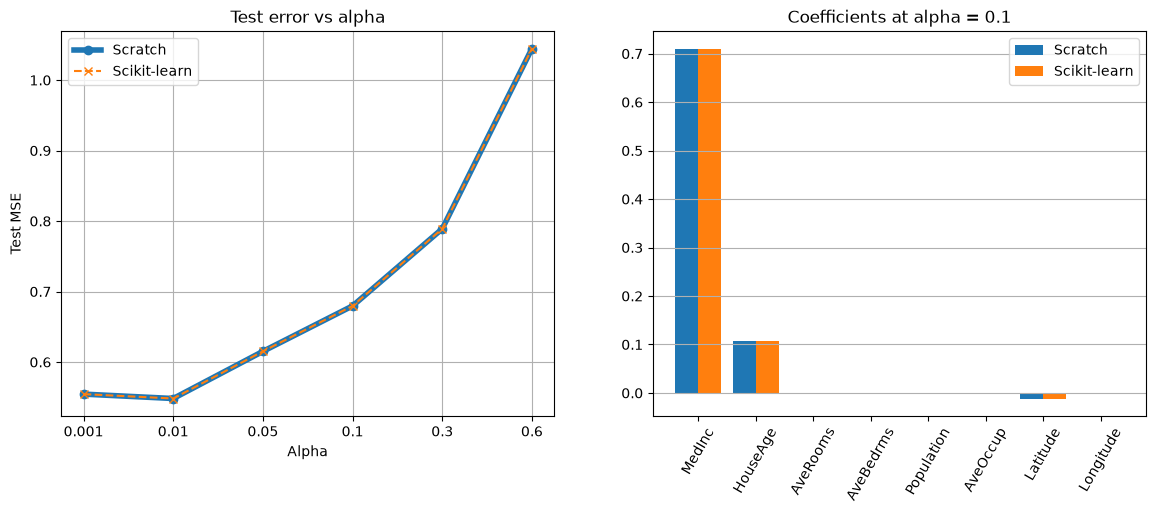

In [23]:
lasso_cmp = pd.DataFrame({
    "Alpha": lasso_alphas,
    "MSE (scratch)": lasso_s_table["MSE"],
    "MSE (Scikit-learn)": lasso_l_table["MSE"],
    "Zero weights (scratch)": lasso_s_table["Zero weights"],
    "Zero weights (Scikit-learn)": lasso_l_table["Zero weights"],
    "Max coef difference": [np.max(np.abs(lasso_s_coef[a] - lasso_l_coef[a])) for a in lasso_alphas]
})
print(lasso_cmp.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(range(len(lasso_alphas)), lasso_s_table["MSE"], marker="o", linewidth=4, label="Scratch")
ax[0].plot(range(len(lasso_alphas)), lasso_l_table["MSE"], marker="x", linestyle="--", label="Scikit-learn")
ax[0].set_xticks(range(len(lasso_alphas)))
ax[0].set_xticklabels(lasso_alphas)
ax[0].set_xlabel("Alpha")
ax[0].set_ylabel("Test MSE")
ax[0].set_title("Test error vs alpha")
ax[0].legend()
ax[0].grid()

pos = np.arange(len(X.columns))
ax[1].bar(pos - 0.2, lasso_s_coef[0.1], width=0.4, label="Scratch")
ax[1].bar(pos + 0.2, lasso_l_coef[0.1], width=0.4, label="Scikit-learn")
ax[1].set_xticks(pos)
ax[1].set_xticklabels(X.columns, rotation=60)
ax[1].set_title("Coefficients at alpha = 0.1")
ax[1].legend()
ax[1].grid(axis="y")

plt.show()

---
# Part 8: Locally Weighted Regression

Normal linear regression fits one line for all the data. Locally weighted regression (LWR) is different: for **every new point** it fits a small model that mostly looks at the training points *near* that point.

Steps for one query point `x0`:

1. Give each training row a weight: `w_i = exp( -||x_i - x0||^2 / (2 * tau^2) )`. Near rows get a weight close to 1, far rows close to 0.
2. Solve the weighted least squares: `theta = (X^T W X)^-1 X^T W y`.
3. Predict with `[1, x0] . theta`.

`tau` (bandwidth) controls how local the model is. A small `tau` follows the data closely (can be noisy), a large `tau` behaves like normal linear regression.

LWR has no training step and needs a new fit for every prediction, so it is slow. To keep the run time small, we test it on 300 random test rows.

### 8A. Locally Weighted Regression from Scratch

One small note: for a very small `tau` almost all weights are close to zero, so the matrix can become hard to solve. We add a tiny number (`1e-6`) to its diagonal to keep it solvable.

Scratch, 300 test rows
 Tau      MAE      MSE
0.25 0.392414 0.312384
0.50 0.427926 0.383875
1.00 0.474508 0.446533
2.00 0.503337 0.497292
4.00 0.519073 0.527520

Plain linear regression on the same rows: MAE = 0.5592, MSE = 0.6095
Best tau: 0.25


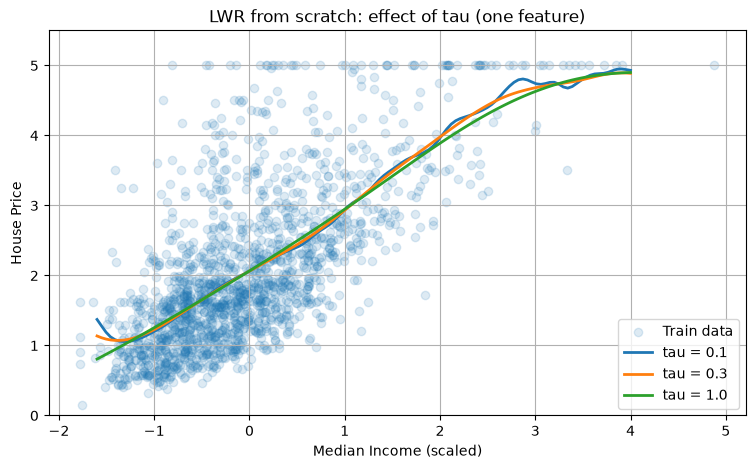

In [24]:
def lwr_predict(x0, Xs, y, tau):
    # weights from the distance to the query point
    dist2 = np.sum((Xs - x0) ** 2, axis=1)
    w = np.exp(-dist2 / (2 * tau ** 2))

    Xb = add_bias(Xs)
    A = Xb.T @ (Xb * w[:, None]) + 1e-6 * np.eye(Xb.shape[1])
    b = Xb.T @ (w * y)
    theta_local = np.linalg.solve(A, b)
    return np.r_[1.0, x0] @ theta_local

# 300 random test rows
rng3 = np.random.RandomState(1)
sub = rng3.choice(len(y_te), 300, replace=False)
Xq = X_test_scaled[sub]
yq = y_te[sub]

taus = [0.25, 0.5, 1, 2, 4]
lwr_s_rows = []
lwr_s_pred = {}

for t in taus:
    p = np.array([lwr_predict(q, X_train_scaled, y_tr, t) for q in Xq])
    lwr_s_pred[t] = p
    lwr_s_rows.append([t, mean_absolute_error(yq, p), mean_squared_error(yq, p)])

lwr_s_table = pd.DataFrame(lwr_s_rows, columns=["Tau", "MAE", "MSE"])
print("Scratch, 300 test rows")
print(lwr_s_table.to_string(index=False))

# plain linear regression on the same rows, for a fair comparison
plain_pred = model.predict(Xq)
print("\nPlain linear regression on the same rows: MAE = %.4f, MSE = %.4f" % (
    mean_absolute_error(yq, plain_pred), mean_squared_error(yq, plain_pred)))

best_tau = lwr_s_table.loc[lwr_s_table["MSE"].idxmin(), "Tau"]
print("Best tau:", best_tau)
add_result("Locally Weighted tau=%s (scratch, 300 rows)" % best_tau, yq, lwr_s_pred[best_tau])

# ---------- one feature only (MedInc), so we can draw the curve ----------
xs_train_2d = xs_tr.reshape(-1, 1)
grid_pts = np.linspace(-1.6, 4, 120)

plt.figure(figsize=(9, 5))
plt.scatter(xs_tr[::10], y_tr[::10], alpha=0.15, label="Train data")
for t in [0.1, 0.3, 1.0]:
    curve = [lwr_predict(np.array([g]), xs_train_2d, y_tr, t) for g in grid_pts]
    plt.plot(grid_pts, curve, linewidth=2, label="tau = %s" % t)
plt.ylim(0, 5.5)
plt.xlabel("Median Income (scaled)")
plt.ylabel("House Price")
plt.title("LWR from scratch: effect of tau (one feature)")
plt.legend()
plt.grid()
plt.show()

### 8B. Locally Weighted Regression with Scikit-learn

Scikit-learn has no ready-made LWR, so we build it from the library: for every query point we work out the weights and call `LinearRegression.fit` with the `sample_weight` option. That does the weighted least squares for us.

Scikit-learn, 300 test rows
 Tau      MAE      MSE
0.25 0.397158 0.332568
0.50 0.428621 0.386538
1.00 0.474508 0.446533
2.00 0.503337 0.497292
4.00 0.519073 0.527520


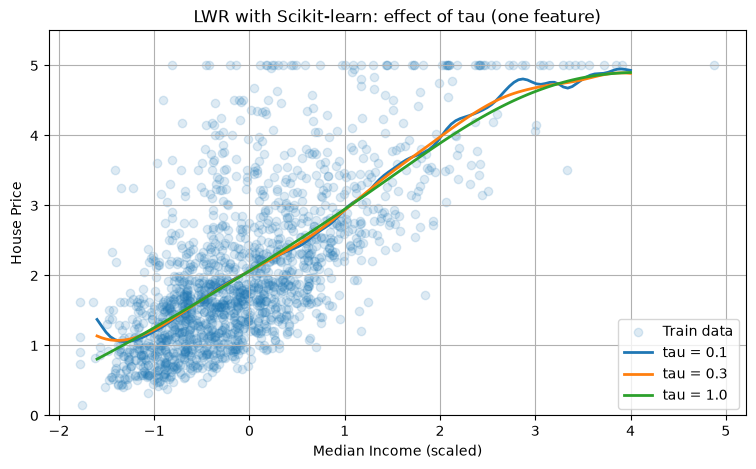

In [25]:
def lwr_predict_lib(x0, Xs, y, tau):
    dist2 = np.sum((Xs - x0) ** 2, axis=1)
    w = np.exp(-dist2 / (2 * tau ** 2))
    m = LinearRegression()
    m.fit(Xs, y, sample_weight=w)
    return m.predict(x0.reshape(1, -1))[0]

lwr_l_rows = []
lwr_l_pred = {}

for t in taus:
    p = np.array([lwr_predict_lib(q, X_train_scaled, y_tr, t) for q in Xq])
    lwr_l_pred[t] = p
    lwr_l_rows.append([t, mean_absolute_error(yq, p), mean_squared_error(yq, p)])

lwr_l_table = pd.DataFrame(lwr_l_rows, columns=["Tau", "MAE", "MSE"])
print("Scikit-learn, 300 test rows")
print(lwr_l_table.to_string(index=False))

add_result("Locally Weighted tau=%s (Scikit-learn, 300 rows)" % best_tau, yq, lwr_l_pred[best_tau])

# ---------- one feature curve ----------
plt.figure(figsize=(9, 5))
plt.scatter(xs_tr[::10], y_tr[::10], alpha=0.15, label="Train data")
for t in [0.1, 0.3, 1.0]:
    curve = [lwr_predict_lib(np.array([g]), xs_train_2d, y_tr, t) for g in grid_pts]
    plt.plot(grid_pts, curve, linewidth=2, label="tau = %s" % t)
plt.ylim(0, 5.5)
plt.xlabel("Median Income (scaled)")
plt.ylabel("House Price")
plt.title("LWR with Scikit-learn: effect of tau (one feature)")
plt.legend()
plt.grid()
plt.show()

### 8C. Comparison: Scratch vs Scikit-learn

 Tau  MSE (scratch)  MSE (Scikit-learn)  Max prediction difference
0.25       0.312384            0.332568               1.316088e+00
0.50       0.383875            0.386538               2.082327e-01
1.00       0.446533            0.446533               5.361837e-06
2.00       0.497292            0.497292               6.691958e-08
4.00       0.527520            0.527520               7.290615e-09


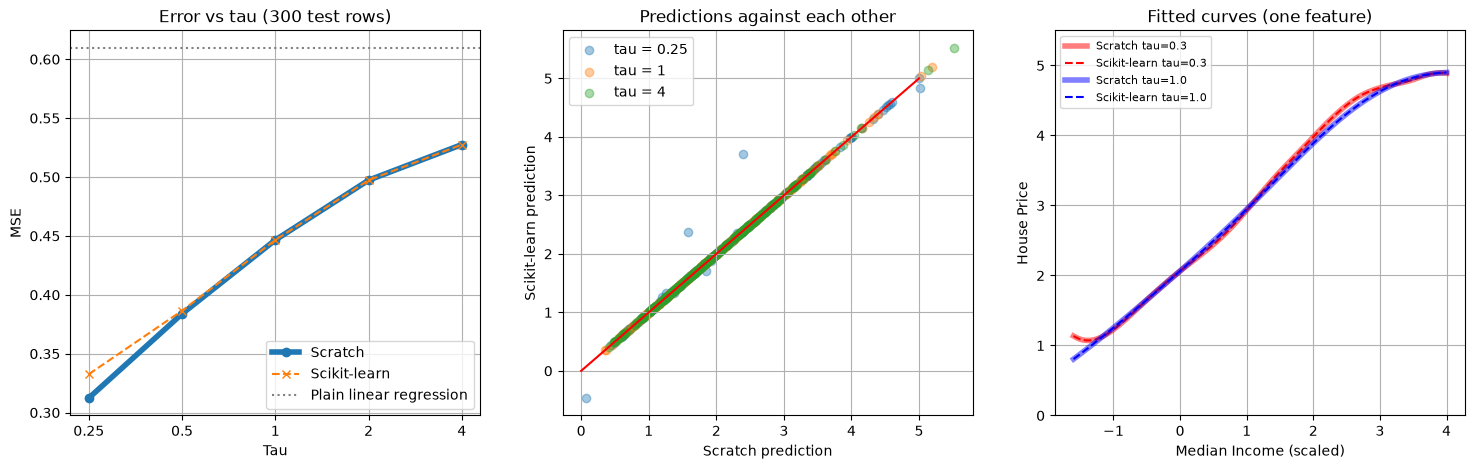

In [26]:
lwr_cmp = pd.DataFrame({
    "Tau": taus,
    "MSE (scratch)": lwr_s_table["MSE"],
    "MSE (Scikit-learn)": lwr_l_table["MSE"],
    "Max prediction difference": [np.max(np.abs(lwr_s_pred[t] - lwr_l_pred[t])) for t in taus]
})
print(lwr_cmp.to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].plot(range(len(taus)), lwr_s_table["MSE"], marker="o", linewidth=4, label="Scratch")
ax[0].plot(range(len(taus)), lwr_l_table["MSE"], marker="x", linestyle="--", label="Scikit-learn")
ax[0].axhline(mean_squared_error(yq, plain_pred), color="gray", linestyle=":", label="Plain linear regression")
ax[0].set_xticks(range(len(taus)))
ax[0].set_xticklabels(taus)
ax[0].set_xlabel("Tau")
ax[0].set_ylabel("MSE")
ax[0].set_title("Error vs tau (300 test rows)")
ax[0].legend()
ax[0].grid()

for t in [0.25, 1, 4]:
    ax[1].scatter(lwr_s_pred[t], lwr_l_pred[t], alpha=0.4, label="tau = %s" % t)
ax[1].plot([0, 5], [0, 5], color="red")
ax[1].set_xlabel("Scratch prediction")
ax[1].set_ylabel("Scikit-learn prediction")
ax[1].set_title("Predictions against each other")
ax[1].legend()
ax[1].grid()

for t, col in [(0.3, "red"), (1.0, "blue")]:
    cs = [lwr_predict(np.array([g]), xs_train_2d, y_tr, t) for g in grid_pts]
    cl = [lwr_predict_lib(np.array([g]), xs_train_2d, y_tr, t) for g in grid_pts]
    ax[2].plot(grid_pts, cs, color=col, linewidth=4, alpha=0.5, label="Scratch tau=%s" % t)
    ax[2].plot(grid_pts, cl, color=col, linestyle="--", label="Scikit-learn tau=%s" % t)
ax[2].set_ylim(0, 5.5)
ax[2].set_xlabel("Median Income (scaled)")
ax[2].set_ylabel("House Price")
ax[2].set_title("Fitted curves (one feature)")
ax[2].legend(fontsize=8)
ax[2].grid()

plt.show()

---
# Part 9: Final Comparison of All Models

Every model is listed below with its MAE and MSE on the test set. Keep in mind:

* The Simple and Polynomial models use only `MedInc`, the others use all 8 features.
* The Locally Weighted rows are measured on 300 test rows only, so they are not exactly the same test set as the other rows.

                                             Model      MAE      MSE
                               Simple LR (scratch) 0.629909 0.709116
                          Simple LR (Scikit-learn) 0.629909 0.709116
                 Multiple LR (scratch, normal eq.) 0.533200 0.555892
                        Multiple LR (Scikit-learn) 0.533200 0.555892
                        Polynomial deg 3 (scratch) 0.621896 0.698296
                   Polynomial deg 3 (Scikit-learn) 0.621896 0.698296
                        Gradient Descent (scratch) 0.547676 0.567185
                   Gradient Descent (SGDRegressor) 0.529883 0.550599
                          Ridge alpha=10 (scratch) 0.533138 0.555535
                     Ridge alpha=10 (Scikit-learn) 0.533138 0.555535
                        Lasso alpha=0.01 (scratch) 0.535331 0.548239
                   Lasso alpha=0.01 (Scikit-learn) 0.535326 0.548255
     Locally Weighted tau=0.25 (scratch, 300 rows) 0.392414 0.312384
Locally Weighted tau=0.25 (Scikit-

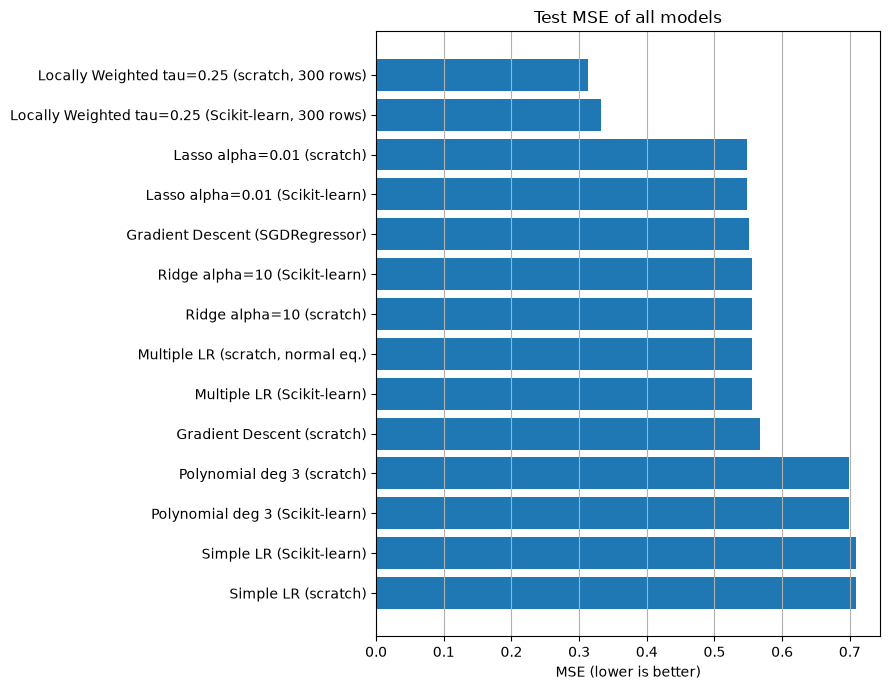

In [27]:
final_table = pd.DataFrame(results, columns=["Model", "MAE", "MSE"])
print(final_table.to_string(index=False))

plt.figure(figsize=(9, 7))
order = final_table.sort_values("MSE", ascending=False)
plt.barh(order["Model"], order["MSE"])
plt.xlabel("MSE (lower is better)")
plt.title("Test MSE of all models")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

### Results

**Simple Linear Regression.** Using only Median Income, the line is about `price = 0.4193 * income + 0.4446`. Our formula and Scikit-learn gave the same slope and intercept, and the same error (MAE 0.6299, MSE 0.7091). One feature is not enough to explain house prices well.

**Multiple Linear Regression.** With all 8 features the MSE fell from 0.7091 to 0.5559. The normal equation we wrote and Scikit-learn gave the same weights (they differ only after the 14th decimal place). Latitude, Longitude and Median Income have the largest weights.

**Polynomial Regression.** On the full data a higher degree helped only a little (MSE 0.7091 at degree 1, 0.6983 at degree 3), because the link between income and price is already close to a line. The scratch and Scikit-learn versions gave the same errors. With only 30 training rows, the high degrees showed clear overfitting. The train error kept going down, but the test error became huge (about 550 at degree 5 and millions at degree 9).

**Gradient Descent.** Our own version (MAE 0.5477, MSE 0.5672) is close to Scikit-learn's `LinearRegression` (MAE 0.5332, MSE 0.5559), but not exactly equal. With a learning rate of 0.01 and 1000 steps, it has not fully reached the best weights yet. You can see this in the weights, for example Latitude and Longitude are still about -0.49 and -0.45, while the exact answer is about -0.90 and -0.87. More iterations or a larger learning rate bring it closer. `SGDRegressor` gave MAE 0.5299 and MSE 0.5506.

**Ridge Regression.** Our closed form version and `Ridge` gave the same results. A small alpha changes almost nothing. A very large alpha (10000) shrinks the weights too much and the MSE rises to 0.7244. A medium alpha (around 100) gave a slightly better MSE (0.5533) than plain regression (0.5559).

**Lasso Regression.** Our coordinate descent matches `Lasso` (the weights agree to within 0.001). Lasso sets weights to exactly zero as alpha grows. At alpha = 0.1, five of the eight weights became zero and only Median Income, House Age and a small Latitude weight were kept. At alpha = 0.01 the MSE (0.5482) was a little lower than plain regression.

**Locally Weighted Regression.** On 300 test rows, plain linear regression had an MSE of 0.6095. LWR did better, and the smaller the `tau`, the better it did here (0.3124 at tau = 0.25, 0.5275 at tau = 4). As `tau` grows, LWR gets closer to plain linear regression, as expected. The scratch and Scikit-learn versions agree for tau of 1 or more, and differ a little for very small tau because of the tiny number we add to keep the matrix solvable.

### Performance Comparison (test set)

| Model | MAE | MSE |
| :--- | :---: | :---: |
| Simple LR (scratch and Scikit-learn) | 0.6299 | 0.7091 |
| Multiple LR (normal equation and Scikit-learn) | 0.5332 | 0.5559 |
| Polynomial degree 3, one feature (scratch and Scikit-learn) | 0.6219 | 0.6983 |
| Gradient Descent (scratch) | 0.5477 | 0.5672 |
| Gradient Descent (SGDRegressor) | 0.5299 | 0.5506 |
| Ridge, alpha = 10 (scratch and Scikit-learn) | 0.5331 | 0.5555 |
| Lasso, alpha = 0.01 (scratch) | 0.5353 | 0.5482 |
| Lasso, alpha = 0.01 (Scikit-learn) | 0.5353 | 0.5483 |
| Locally Weighted, tau = 0.25 (scratch), 300 rows | 0.3924 | 0.3124 |
| Locally Weighted, tau = 0.25 (Scikit-learn), 300 rows | 0.3972 | 0.3326 |

The Locally Weighted rows use only 300 test rows, so they should not be compared one to one with the other rows.

---

### Outcomes:

1. Built Simple, Multiple and Polynomial Linear Regression, each from scratch and with Scikit-learn, and got matching answers.
2. Wrote Gradient Descent by hand and studied the effect of learning rate and number of iterations.
3. Saw why feature scaling matters for Gradient Descent, Ridge and Lasso.
4. Saw overfitting happen with a high degree polynomial on a small sample.
5. Wrote Ridge Regression with its closed form answer and saw weights shrink as alpha grows.
6. Wrote Lasso Regression with coordinate descent and saw weights become exactly zero.
7. Wrote Locally Weighted Regression and saw how `tau` controls how local the fit is.
8. Compared scratch and library versions of every model with tables and plots.
9. Compared all models using MAE and MSE.

---

### Summary & Conclusion

In this experiment we built seven kinds of linear regression on the California housing data, and for each one we wrote our own version, used the library version, and compared the two. In almost every case the two matched closely, which shows that the from-scratch code is correct.

Using more features helped the most: going from one feature to all eight cut the MSE from 0.71 to 0.56. Making the curve more complex with polynomial terms helped very little on the full data and caused overfitting on a small sample. Ridge and Lasso did not change the score much here, because the model was not overfitting, but Lasso showed how it can drop unneeded features. Gradient Descent needs a good learning rate and enough steps, otherwise it stops short of the best answer. Locally Weighted Regression gave the lowest error, but it needs a new fit for every prediction, so it is slow on large data.